In [1]:
# Initialization, styling configuration, and helper utilities
%matplotlib inline

import math

import matplotlib.image as mpimg
import pandas as pd
import seaborn as sns
import torch
from IPython.display import Markdown, display
from ipywidgets import interact

# Course helpers: installed from PyPI in Colab, from the repository's .venv locally
import sys
if "google.colab" in sys.modules:
    %pip install -q dl-course
from dl_course import foundations as hp

hp.setup_theme()

# Linear Algebra for Deep Learning

- Linear algebra provides the universal mathematical language for representation, geometry, and optimization in machine learning:
  - **Data Representations**: High-dimensional features, embeddings, and structured inputs are represented as vectors, matrices, and tensors.
  - **Linear Transformations**: Layers in deep neural networks compose affine mappings ($\mathbf{W}\mathbf{x} + \mathbf{b}$) with elementwise non-linearities.
  - **Optimization Curvature**: Gradients, Hessian matrices, and condition numbers govern the convergence dynamics of gradient descent.
  - **Dimensionality Reduction**: Spectral and singular value decompositions uncover dominant latent subspaces and compress representations.

<small>📖 *Source: [Bishop, C. M. & Bishop, H. (2024). Deep Learning: Foundations and Concepts. Springer](https://doi.org/10.1007/978-3-031-45468-4)*</small><br>
<small>📖 *Source: [Deisenroth, M. P., Faisal, A. A. & Ong, C. S. (2020). Mathematics for Machine Learning. Cambridge University Press](https://doi.org/10.1017/9781108679930)*</small><br>
<small>📖 *Source: [Strang, G. (2019). Linear Algebra and Learning from Data. Wellesley-Cambridge Press](https://math.mit.edu/~gs/learningfromdata/)*</small>

> 📝 **Note:** The appendix at the end of this notebook holds self-study material that later lectures do not rely on: matrix norms and the matrix identities (push-through, Woodbury, determinant lemma).

## Vectors and Vector Spaces

- A **scalar** is an individual numerical quantity: $x \in \mathbb{R}$.
- A **vector** is an ordered collection of numbers representing a point or directional displacement in a $D$-dimensional real vector space $\mathbb{R}^D$.
- Vectors are assumed to be **column vectors**:
$$\mathbf{x} = \begin{bmatrix} x_1 \\ x_2 \\ \vdots \\ x_D \end{bmatrix} \in \mathbb{R}^D$$
- The compact notation $(x_1, \dots, x_D)$ denotes a row vector, and the column vector is written as $\mathbf{x} = (x_1, \dots, x_D)^\mathrm{T}$.
- **Vector Concatenation**: $\mathbf{a} \oplus \mathbf{b}$ denotes the concatenation of $\mathbf{a} \in \mathbb{R}^N$ and $\mathbf{b} \in \mathbb{R}^M$ into a combined vector in $\mathbb{R}^{N+M}$:
$$\mathbf{a} \oplus \mathbf{b} = (a_1, \dots, a_N, b_1, \dots, b_M)^\mathrm{T}$$


Vector $\mathbf{v}$:

[[ 1.]
 [-2.]]


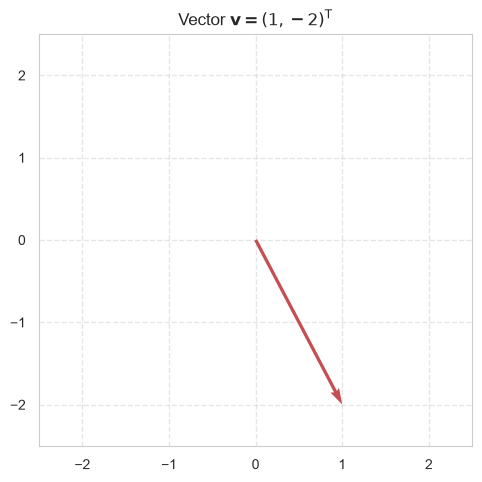

In [2]:
# Visualizing a 2D column vector
v_sample = torch.tensor([[1.0], [-2.0]], dtype=torch.float32)
display(Markdown(r"Vector $\mathbf{v}$:"))
print(v_sample.numpy())
hp.plot2d(v_sample, title=r"Vector $\mathbf{v} = (1, -2)^\mathrm{T}$");

## Vector Scaling

- Multiplication of a vector $\mathbf{x}$ by a scalar $\alpha \in \mathbb{R}$ scales the magnitude of the vector along its line of action:
$$\alpha \mathbf{x} = (\alpha x_1, \alpha x_2, \dots, \alpha x_D)^\mathrm{T}$$
- If $\alpha > 0$, the vector preserves its orientation.
- If $\alpha < 0$, the vector reverses its direction.
- If $\alpha = 0$, it collapses to the origin zero vector $\mathbf{0}$.


In [3]:
# Vector scaling implementation
x_vec = torch.tensor([[1.0], [-2.0]], dtype=torch.float32)

def scale_vector(alpha=1):
    """Scale vector by scalar factor alpha and visualize."""
    x_scaled = x_vec * alpha
    display(Markdown(rf"Scalar $\alpha = {alpha:+d}$ | Scaled vector $\alpha \mathbf{{x}} = "
                     rf"({x_scaled[0, 0].item():+.1f}, "
                     rf"{x_scaled[1, 0].item():+.1f})^\mathrm{{T}}$"))
    if alpha != 0:
        hp.plot2d(torch.cat((x_vec, x_scaled), dim=1), title=rf"Scale factor $\alpha = {alpha}$")
    else:
        hp.plot2d(x_vec, title=r"Scale factor $\alpha = 0$")

In [4]:
# Interactive exploration of scalar multiplication
interact(scale_vector, alpha=(-2, 2, 1));

interactive(children=(IntSlider(value=1, description='alpha', max=2, min=-2), Output()), _dom_classes=('widget…

## Inner Product and Orthogonality

- The **inner product** (or dot product) of vectors $\mathbf{x}, \mathbf{y} \in \mathbb{R}^D$ is defined as:
$$\mathbf{x}^\mathrm{T}\mathbf{y} = \sum_{i=1}^D x_i y_i$$
- **Properties**:
  - Commutativity: $\mathbf{x}^\mathrm{T}\mathbf{y} = \mathbf{y}^\mathrm{T}\mathbf{x}$
  - Bilinearity: $(\alpha \mathbf{x}_1 + \beta \mathbf{x}_2)^\mathrm{T}\mathbf{y} = \alpha \mathbf{x}_1^\mathrm{T}\mathbf{y} + \beta \mathbf{x}_2^\mathrm{T}\mathbf{y}$
- **Orthogonality**: Two vectors are orthogonal (perpendicular) if and only if their inner product vanishes:
$$\mathbf{x}^\mathrm{T}\mathbf{y} = 0$$
- **Orthonormality**: A set of vectors $\{\mathbf{u}_i\}$ is orthonormal if they are pairwise orthogonal and unit length:
$$\mathbf{u}_i^\mathrm{T}\mathbf{u}_j = \delta_{ij} = \begin{cases} 1 & \text{if } i = j \\ 0 & \text{if } i \neq j \end{cases}$$


$\mathbf{x}^\mathrm{T}\mathbf{y} = 0.0000, \quad \mathbf{y}^\mathrm{T}\mathbf{x} = 0.0000$ (Strictly commutative)

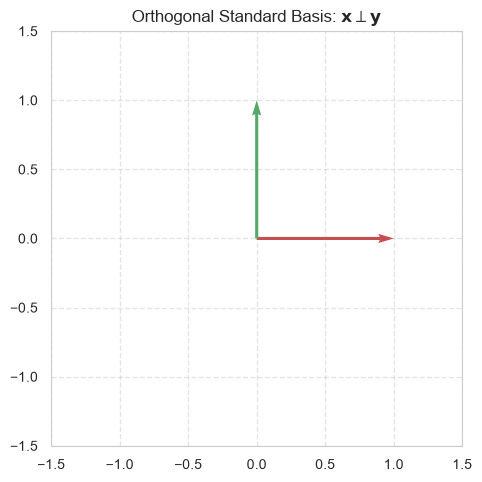

In [5]:
x_pt = torch.tensor([[1.0], [0.0]])
y_pt = torch.tensor([[0.0], [1.0]])
xy_dot = torch.matmul(x_pt.t(), y_pt).item()
yx_dot = torch.matmul(y_pt.t(), x_pt).item()
display(Markdown(rf"$\mathbf{{x}}^\mathrm{{T}}\mathbf{{y}} = {xy_dot:.4f}, \quad "
                 rf"\mathbf{{y}}^\mathrm{{T}}\mathbf{{x}} = {yx_dot:.4f}$ (Strictly "
                 r"commutative)"))
hp.plot2d(torch.cat((x_pt, y_pt), dim=1), title=r"Orthogonal Standard Basis: "
                                                r"$\mathbf{x} \perp \mathbf{y}$");

## Vector Norms

- A **norm** $\|\mathbf{x}\|$ is a function measuring the magnitude or length of a vector $\mathbf{x} \in \mathbb{R}^D$ satisfying:
  1. **Non-negativity & Identity of Indiscernibles**: $\|\mathbf{x}\| \ge 0$, and $\|\mathbf{x}\| = 0 \iff \mathbf{x} = \mathbf{0}$
  2. **Absolute Homogeneity**: $\|\alpha \mathbf{x}\| = |\alpha| \cdot \|\mathbf{x}\|$ for all $\alpha \in \mathbb{R}$
  3. **Triangle Inequality**: $\|\mathbf{x} + \mathbf{y}\| \le \|\mathbf{x}\| + \|\mathbf{y}\|$
- The generalized $L_p$ norm ($p \ge 1$) is defined as:
$$\|\mathbf{x}\|_p = \left( \sum_{i=1}^D |x_i|^p \right)^{1/p}$$

## Euclidean Norm and Angles

- The **$L_2$ norm** (Euclidean length) corresponds to $p = 2$:
$$\|\mathbf{x}\|_2 = \left( \sum_{i=1}^D x_i^2 \right)^{1/2} = \sqrt{\mathbf{x}^\mathrm{T}\mathbf{x}}$$
- The squared $L_2$ norm $\|\mathbf{x}\|_2^2 = \mathbf{x}^\mathrm{T}\mathbf{x}$ is ubiquitous in deep learning (e.g. weight decay, sum-of-squares error) because its gradient is smooth and linear: $\nabla_\mathbf{x} \|\mathbf{x}\|_2^2 = 2\mathbf{x}$.
- **Geometric Inner Product**:
$$\mathbf{x}^\mathrm{T}\mathbf{y} = \|\mathbf{x}\|_2 \|\mathbf{y}\|_2 \cos \theta$$
  where $\theta$ is the angle between $\mathbf{x}$ and $\mathbf{y}$.
- The cosine similarity is thus: $\cos \theta = \frac{\mathbf{x}^\mathrm{T}\mathbf{y}}{\|\mathbf{x}\|_2 \|\mathbf{y}\|_2}$.

In [6]:
# Inner product, cosine similarity, and angle computation
def inspect_angle(y1=0.0, y2=1.0):
    """Inspect angle and inner product between x = (1, 0) and y = (y1, y2)."""
    x_base = torch.tensor([[1.0], [0.0]], dtype=torch.float32)
    y_comp = torch.tensor([[y1], [y2]], dtype=torch.float32)
    dot_prod = torch.matmul(x_base.t(), y_comp).item()
    norm_product = (torch.norm(x_base) * torch.norm(y_comp)).item()
    if norm_product < 1e-8:
        display(Markdown(r"$\mathbf{y} = \mathbf{0}$: the angle is undefined, because "
                         r"$\|\mathbf{y}\|_2 = 0$"))
        return
    cos_val = max(-1.0, min(1.0, dot_prod / norm_product))
    deg = math.degrees(math.acos(cos_val))
    display(Markdown(r"Inner product "
                     rf"$\mathbf{{x}}^\mathrm{{T}}\mathbf{{y}} = {dot_prod:.3f}$, cosine "
                     rf"$\cos\theta = {cos_val:.3f}$, angle $\theta = {deg:.1f}^\circ$"))
    hp.plot2d(torch.cat((x_base, y_comp), dim=1), title=r"$\mathbf{x}^\mathrm{T}\mathbf{y} "
                                                        rf"= {dot_prod:.2f}$, $\theta = "
                                                        rf"{deg:.1f}^\circ$")

In [7]:
# Interactive exploration of vector angles and inner products
interact(inspect_angle, y1=(-1.0, 1.0, 0.1), y2=(-1.0, 1.0, 0.1));

interactive(children=(FloatSlider(value=0.0, description='y1', max=1.0, min=-1.0), FloatSlider(value=1.0, desc…

## $L_1$, $L_\infty$, and $L_0$ Norms

- **$L_1$ norm (Manhattan / Taxicab)**:
$$\|\mathbf{x}\|_1 = \sum_{i=1}^D |x_i|$$
  - Widely used as a sparsity-inducing regularizer (Lasso). Drives unimportant weights exactly to zero.
- **$L_\infty$ norm (Chebyshev / Maximum norm)**:
$$\|\mathbf{x}\|_\infty = \max_{1 \le i \le D} |x_i|$$
  - Used in adversarial robustness ($L_\infty$-bounded adversarial perturbations).
- **$L_0$ Pseudo-norm**:
$$\|\mathbf{x}\|_0 = \sum_{i=1}^D \mathbb{I}(x_i \neq 0)$$
  - Counts non-zero elements. Not a true norm (violates absolute homogeneity).

## Hyperplanes and Linear Classifiers

- A linear decision boundary is the **hyperplane** $y(\mathbf{x}) = \mathbf{w}^\mathrm{T}\mathbf{x} + w_0 = 0$ in $\mathbb{R}^D$.
- For two points $\mathbf{x}_A, \mathbf{x}_B$ on it, $\mathbf{w}^\mathrm{T}(\mathbf{x}_A - \mathbf{x}_B) = 0$: the weight vector $\mathbf{w}$ is **orthogonal** to every direction within the surface.
- The signed distance of a point $\mathbf{x}$ from the hyperplane is
$$r = \frac{y(\mathbf{x})}{\|\mathbf{w}\|}$$
- Decision boundaries, their geometry and the perceptron follow in *(→ Lecture 05_classification)*.

<small>📖 *Source: [Bishop, C. M. & Bishop, H. (2024). Deep Learning: Foundations and Concepts. Springer (Section 5.1.1, Figure 5.1)](https://doi.org/10.1007/978-3-031-45468-4)*</small>

## Matrices and Linear Mappings

- A **matrix** $\mathbf{A} \in \mathbb{R}^{M \times N}$ is a two-dimensional array of elements with $M$ rows and $N$ columns:
$$\mathbf{A} = \begin{bmatrix} A_{11} & A_{12} & \cdots & A_{1N} \\ A_{21} & A_{22} & \cdots & A_{2N} \\ \vdots & \vdots & \ddots & \vdots \\ A_{M1} & A_{M2} & \cdots & A_{MN} \end{bmatrix}$$
- In deep learning, an input batch of $N$ observations with $D$ features is represented as a **data matrix** $\mathbf{X} \in \mathbb{R}^{N \times D}$, where row $n$ corresponds to $\mathbf{x}_n^\mathrm{T}$.
- Linear layer parameters form a **weight matrix** $\mathbf{W} \in \mathbb{R}^{M \times D}$, mapping input $\mathbf{x} \in \mathbb{R}^D$ to output activation $\mathbf{a} = \mathbf{W}\mathbf{x} \in \mathbb{R}^M$.


In [8]:
mat_sample = torch.tensor([[1.0, -2.0, 3.0], [3.0, -2.0, -2.0]], dtype=torch.float32)
display(Markdown(r"Sample matrix $\mathbf{A} \in \mathbb{R}^{2 \times 3}$:"))
print(mat_sample.numpy())
display(Markdown(r"First column (`A[:, 0]`) and first row (`A[0, :]`):"))
print(mat_sample[:, 0].numpy(), mat_sample[0, :].numpy())

Sample matrix $\mathbf{A} \in \mathbb{R}^{2 \times 3}$:

[[ 1. -2.  3.]
 [ 3. -2. -2.]]


First column (`A[:, 0]`) and first row (`A[0, :]`):

[1. 3.] [ 1. -2.  3.]


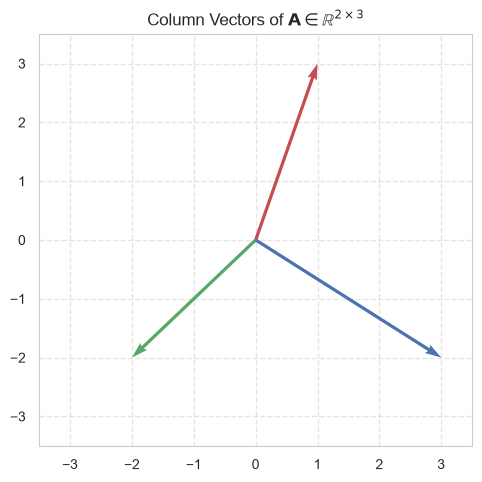

In [9]:
hp.plot2d(mat_sample, title=r"Column Vectors of $\mathbf{A} \in \mathbb{R}^{2 \times 3}$");

## Matrix Transpose and Symmetry

- The **transpose** $\mathbf{A}^\mathrm{T} \in \mathbb{R}^{N \times M}$ mirrors elements across the main diagonal: $(\mathbf{A}^\mathrm{T})_{ij} = A_{ji}$.
- **Properties**:
  - $(\mathbf{A}^\mathrm{T})^\mathrm{T} = \mathbf{A}$
  - $(\mathbf{A} + \mathbf{B})^\mathrm{T} = \mathbf{A}^\mathrm{T} + \mathbf{B}^\mathrm{T}$
  - $(\mathbf{A}\mathbf{B})^\mathrm{T} = \mathbf{B}^\mathrm{T}\mathbf{A}^\mathrm{T}$
  - $(\mathbf{A}^\mathrm{T})^{-1} = (\mathbf{A}^{-1})^\mathrm{T}$
- **Symmetric Matrix**: A square matrix $\mathbf{A} \in \mathbb{R}^{M \times M}$ is symmetric if $\mathbf{A}^\mathrm{T} = \mathbf{A}$ ($A_{ij} = A_{ji}$).
  - Covariance matrices $\boldsymbol{\Sigma}$, Gram matrices $\mathbf{X}\mathbf{X}^\mathrm{T}$, and Hessian matrices $\mathbf{H}$ are fundamentally symmetric.


## Matrix Operations and Broadcasting

- **Matrix Addition**: For matrices of matching shape $(M \times N)$, $(\mathbf{A} + \mathbf{B})_{ij} = A_{ij} + B_{ij}$.
- **Broadcasting**: adding a bias vector $\mathbf{b} \in \mathbb{R}^D$ to every row of a data matrix $\mathbf{X} \in \mathbb{R}^{N \times D}$ is $\mathbf{X} + \mathbf{1}\mathbf{b}^\mathrm{T}$, with the all-ones vector $\mathbf{1} \in \mathbb{R}^N$. Frameworks replicate $\mathbf{b}$ across the $N$ rows without copying it in memory:
$$(\mathbf{X} + \mathbf{1}\mathbf{b}^\mathrm{T})_{nd} = X_{nd} + b_d$$
- **Matrix Multiplication**: If $\mathbf{A} \in \mathbb{R}^{M \times K}$ and $\mathbf{B} \in \mathbb{R}^{K \times N}$, the product $\mathbf{C} = \mathbf{A}\mathbf{B} \in \mathbb{R}^{M \times N}$ has elements:
$$C_{ij} = \sum_{k=1}^K A_{ik} B_{kj}$$
- **Properties**:
  - Associativity: $\mathbf{A}(\mathbf{B}\mathbf{C}) = (\mathbf{A}\mathbf{B})\mathbf{C}$
  - Distributivity: $\mathbf{A}(\mathbf{B} + \mathbf{C}) = \mathbf{A}\mathbf{B} + \mathbf{A}\mathbf{C}$
  - **Non-commutative**: $\mathbf{A}\mathbf{B} \neq \mathbf{B}\mathbf{A}$ in general!

In [10]:
# 2D rotation matrix application
def rotate_vector(alpha=90):
    """Rotate base vector (1, 0) by angle alpha degrees."""
    rad = math.radians(alpha)
    rot_mat = torch.tensor([[math.cos(rad), -math.sin(rad)], [math.sin(rad), math.cos(rad)]],
                           dtype=torch.float32)
    v_init = torch.tensor([[1.0], [0.0]], dtype=torch.float32)
    v_rot = torch.matmul(rot_mat, v_init)
    display(Markdown(rf"Angle ${alpha:.0f}^\circ$: rotated vector $\mathbf{{v}}_\mathrm{{rot}} "
                     rf"= ({v_rot[0,0].item():.3f}, {v_rot[1,0].item():.3f})^\mathrm{{T}}$"))
    hp.plot2d(torch.cat((v_rot, v_init), dim=1), title=rf"Rotation by $\alpha = {alpha}^\circ$")

In [11]:
# Interactive exploration of 2D linear rotation mapping
interact(rotate_vector, alpha=(0, 360, 15));


interactive(children=(IntSlider(value=90, description='alpha', max=360, step=15), Output()), _dom_classes=('wi…

## Matrix Trace and Trace Properties

- The **trace** $\mathrm{Tr}(\mathbf{A})$ of a square matrix $\mathbf{A} \in \mathbb{R}^{M \times M}$ is the sum of its diagonal entries:
$$\mathrm{Tr}(\mathbf{A}) = \sum_{i=1}^M A_{ii}$$
- **Cyclic Property**: The trace operator is invariant to cyclic permutations of matrix products:
$$\mathrm{Tr}(\mathbf{A}\mathbf{B}\mathbf{C}) = \mathrm{Tr}(\mathbf{C}\mathbf{A}\mathbf{B}) = \mathrm{Tr}(\mathbf{B}\mathbf{C}\mathbf{A})$$
- **Trace and Eigenvalues**: For any square matrix with eigenvalues $\lambda_1, \dots, \lambda_M$ (see *Matrix Decompositions and Spectral Theory* below):
$$\mathrm{Tr}(\mathbf{A}) = \sum_{i=1}^M \lambda_i$$

> 📝 **Note:** Matrix norms (Frobenius, spectral) and further matrix identities (push-through, Woodbury, determinant lemma) are in the appendix *(→ Appendix A1, A2)*.

In [12]:
# Numerical check of the cyclic property of the trace
torch.manual_seed(42)
# Cyclic property of trace
A_tr, B_tr, C_tr = torch.randn(3, 4), torch.randn(4, 3), torch.randn(3, 3)
tr_abc = torch.trace(A_tr @ B_tr @ C_tr).item()
tr_cab = torch.trace(C_tr @ A_tr @ B_tr).item()

display(Markdown(r"Cyclic trace: "
                 rf"$\mathrm{{Tr}}(\mathbf{{A}}\mathbf{{B}}\mathbf{{C}}) = {tr_abc:.4f}$, "
                 rf"$\mathrm{{Tr}}(\mathbf{{C}}\mathbf{{A}}\mathbf{{B}}) = {tr_cab:.4f}$"))

Cyclic trace: $\mathrm{Tr}(\mathbf{A}\mathbf{B}\mathbf{C}) = 2.6360$, $\mathrm{Tr}(\mathbf{C}\mathbf{A}\mathbf{B}) = 2.6360$

# Matrix Calculus Foundations

- Deriving parameter updates and training criteria requires computing derivatives of scalars, vectors, and matrices with respect to tensors.
- **Vector Derivatives of Linear and Quadratic Forms**:
$$\nabla_\mathbf{x} (\mathbf{w}^\mathrm{T}\mathbf{x}) = \mathbf{w}, \qquad \nabla_\mathbf{w} (\mathbf{w}^\mathrm{T}\mathbf{x}) = \mathbf{x}$$
$$\nabla_\mathbf{x} (\mathbf{x}^\mathrm{T}\mathbf{A}\mathbf{x}) = (\mathbf{A} + \mathbf{A}^\mathrm{T})\mathbf{x} = 2\mathbf{A}\mathbf{x} \quad (\text{when } \mathbf{A} = \mathbf{A}^\mathrm{T})$$
- **Derivative of Matrix Inverse**:
$$\frac{\partial \mathbf{A}^{-1}}{\partial x} = -\mathbf{A}^{-1} \frac{\partial \mathbf{A}}{\partial x} \mathbf{A}^{-1}$$
- **Trace and Log-Determinant Derivatives**:
$$\frac{\partial}{\partial \mathbf{A}} \mathrm{Tr}(\mathbf{A}\mathbf{B}) = \mathbf{B}^\mathrm{T}, \qquad \frac{\partial}{\partial \mathbf{A}} \ln \det \mathbf{A} = (\mathbf{A}^{-1})^\mathrm{T}$$

<small>📖 *Source: [Bishop, C. M. & Bishop, H. (2024). Deep Learning: Foundations and Concepts. Springer (Appendix A.3)](https://doi.org/10.1007/978-3-031-45468-4)*</small>

In [13]:
# Verification of vector and quadratic form gradients using PyTorch autograd
x_val = torch.tensor([1.5, -2.0, 3.0], requires_grad=True)
w_fixed = torch.tensor([0.5, 2.0, -1.0])
A_sym = torch.tensor([[2.0, 0.5, 0.0], [0.5, 3.0, 1.0], [0.0, 1.0, 2.5]])

# Linear form gradient
linear_out = torch.dot(w_fixed, x_val)
grad_linear = torch.autograd.grad(linear_out, x_val, retain_graph=True)[0]
display(Markdown(r"Autograd $\nabla_\mathbf{x} (\mathbf{w}^\mathrm{T} \mathbf{x}) = "
                 rf"{hp.format_vector(grad_linear, digits=1)}$"))
display(Markdown(rf"Analytical $\mathbf{{w}} = {hp.format_vector(w_fixed, digits=1)}$"))

Autograd $\nabla_\mathbf{x} (\mathbf{w}^\mathrm{T} \mathbf{x}) = (0.5, 2, -1)^\mathrm{T}$

Analytical $\mathbf{w} = (0.5, 2, -1)^\mathrm{T}$

In [14]:
# Quadratic form gradient
quad_out = torch.dot(x_val, torch.matmul(A_sym, x_val))
grad_quad = torch.autograd.grad(quad_out, x_val)[0]
display(Markdown(r"Autograd $\nabla_\mathbf{x} (\mathbf{x}^\mathrm{T} \mathbf{A} "
                 rf"\mathbf{{x}}) = {hp.format_vector(grad_quad, digits=2)}$"))
display(Markdown(r"Analytical $2 \mathbf{A} \mathbf{x} = "
                 rf"{hp.format_vector(2 * torch.matmul(A_sym, x_val.detach()), digits=2)}$"))

Autograd $\nabla_\mathbf{x} (\mathbf{x}^\mathrm{T} \mathbf{A} \mathbf{x}) = (4, -4.5, 11)^\mathrm{T}$

Analytical $2 \mathbf{A} \mathbf{x} = (4, -4.5, 11)^\mathrm{T}$

## Tensors in Modern Deep Learning

- A **tensor** is a multidimensional array extending scalars (order 0), vectors (order 1), and matrices (order 2) to arbitrary dimensions (order $\ge 3$).
- **Canonical Tensor Shapes in Modern Frameworks**:
  - **Computer Vision (CNNs)**: 4D tensors with shape $(B, C, H, W)$:
    - $B$: Batch size (mini-batch parallelization)
    - $C$: Number of channels (e.g. 3 for RGB, 64–512 for feature maps)
    - $H, W$: Spatial image height and width
  - **Natural Language Processing (Transformers)**: 3D tensors with shape $(B, T, D)$:
    - $B$: Batch size
    - $T$: Sequence length (number of tokens)
    - $D$: Embedding / hidden dimension


## Batched Operations and Computational Benefits

- **Batched Matrix Multiplication (`torch.bmm`)**:
  Computes $B$ simultaneous matrix multiplications: $(B \times P \times Q) \times (B \times Q \times R) \to (B \times P \times R)$:
$$\mathbf{Y}_b = \mathbf{X}_b \mathbf{W}_b \qquad (b = 1, \dots, B)$$
- **Computational and Architectural Benefits**:
  1. **Hardware Parallelism**: One call keeps thousands of GPU cores busy (on NVIDIA GPUs: streaming multiprocessors and Tensor Cores).
  2. **Eliminates Loop Overhead**: Completely avoids Python-level loops over samples in a mini-batch.
  3. **Memory Throughput**: Contiguous memory access maximizes cache lines and DRAM burst transfers.

> 📝 **Note:** The next slides time both effects. Timings depend on the machine: the stored outputs come from a Mac with an Apple GPU (`mps`). In Colab, select a GPU runtime (*Runtime → Change runtime type*) to see `cuda` timings; without a GPU, only the CPU columns appear.

In [15]:
# Timing tools for CPU and GPU: an NVIDIA GPU (cuda), an Apple GPU (mps), or none
import statistics
import time

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")


def synchronize(device: torch.device) -> None:
    """Wait until all queued operations on the device have finished (GPU calls return before
    the work is done)."""
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()


def time_ms(fn, device: torch.device, repeats: int = 5) -> float:
    """Median wall-clock time of fn() in milliseconds, after one warm-up call (the first GPU
    call includes setup costs)."""
    fn()
    times = []
    for _ in range(repeats):
        synchronize(device)
        start = time.perf_counter()
        fn()
        synchronize(device)
        times.append((time.perf_counter() - start) * 1e3)
    return statistics.median(times)


def loop_matmul(X: torch.Tensor, W: torch.Tensor) -> torch.Tensor:
    """One matrix product per sample in a Python loop: B separate calls and B small result
    tensors, which torch.stack copies into one."""
    return torch.stack([X[b] @ W[b] for b in range(X.shape[0])])


note = " (no GPU: only CPU timings below)" if device.type == "cpu" else ""
display(Markdown(f"Accelerator found: `{device.type}`{note}"))

Accelerator found: `mps`

In [16]:
def compare_loop_bmm(B: int = 1000) -> None:
    """Time a Python loop and one bmm call for B products of 16 x 16 matrices on CPU and GPU."""
    n = 16
    devices = [torch.device("cpu")] + ([device] if device.type != "cpu" else [])
    torch.manual_seed(0)
    X_batch = torch.randn(B, n, n)
    W_batch = torch.randn(B, n, n)
    # B products, each n^2 inner products of length n: about 2 n^3 FLOP per product
    gflop = 2 * B * n**3 / 1e9

    header = "| Batch $B$ |" + "".join(f" {d.type.upper()} loop (ms) | {d.type.upper()} `bmm` "
                                       "(ms) |" for d in devices)
    row = f"| {B} |"
    throughput = []
    for d in devices:
        X_d, W_d = X_batch.to(d), W_batch.to(d)
        assert torch.allclose(loop_matmul(X_d, W_d), torch.bmm(X_d, W_d), atol=1e-5)
        t_loop = time_ms(lambda: loop_matmul(X_d, W_d), d)
        t_bmm = time_ms(lambda: torch.bmm(X_d, W_d), d)
        row += f" {t_loop:.2f} | {t_bmm:.3f} |"
        for name, t in [("loop", t_loop), ("`bmm`", t_bmm)]:
            throughput.append(f"- {d.type.upper()} {name}: ${gflop:.4f}\\ \\mathrm{{GFLOP}} / "
                              f"({t:.3f} \\cdot 10^{{-3}}\\ \\mathrm{{s}}) \\approx "
                              f"{gflop / t * 1e3:.1f}\\ \\mathrm{{GFLOP/s}}$")

    note = "" if device.type != "cpu" else "\n\nNo GPU found: CPU timings only."
    display(Markdown(
        f"$B$ products of ${n} \\times {n}$ matrices; loop and `bmm` give the same "
        "$\\mathbf{Y}$.\n\n"
        f"Work: $2 \\cdot B \\cdot {n}^3 = 2 \\cdot {B} \\cdot {n}^3 \\approx {gflop:.4f}$ "
        "GFLOP.\n\n"
        + header + "\n|" + " --: |" * (1 + 2 * len(devices)) + "\n" + row + note
        + "\n\nThroughput (floating-point operations per second):\n\n" + "\n".join(throughput)
    ))

In [17]:
interact(compare_loop_bmm, B=(100, 1000, 100));

interactive(children=(IntSlider(value=1000, description='B', max=1000, min=100, step=100), Output()), _dom_cla…

> 💡 **Key Takeaway:**
> - The loop pays for every sample: one Python call, one small result tensor, and one more copy in `torch.stack`.
> - On the CPU, `bmm` also computes the products one after another, only without this overhead: both times grow with $B$, and the gap stays roughly constant.
> - On a GPU, every call also has a fixed launch cost, so the loop's time grows with $B$, while one `bmm` call computes all products in parallel and barely slows down. For tiny problems the launch cost dominates and the CPU is faster.
> - The GPU pays off for large batches and when the data stays on the device for many operations, as in a training loop: copying it there costs time as well.

## Rearranging Tensors: `view`, `transpose`, `permute`, `unsqueeze`

- Four PyTorch operations change how the numbers of a tensor are arranged, not the numbers themselves:

| Operation | What it does | Example of shapes |
| :-- | :-- | :-- |
| `x.view(...)` | reads the same numbers, row by row, with a new shape | $(6) \to (2, 3)$ |
| `x.transpose(i, j)` | swaps two axes | $(2, 3) \to (3, 2)$ |
| `x.permute(...)` | reorders all axes | $(2, 3, 4) \to (3, 2, 4)$ with `permute(1, 0, 2)` |
| `x.unsqueeze(i)` | inserts an axis of length $1$, e.g. for broadcasting | $(3) \to (3, 1)$ |

### Example of tensor rearrangements
- **Given:** two tensors $\mathbf{U}, \mathbf{V} \in \mathbb{R}^{B \times N \times M}$, i.e. $B$ pairs of matrices $\mathbf{U}_b, \mathbf{V}_b \in \mathbb{R}^{N \times M}$ ($b = 1, \dots, B$), e.g. a batch of $B$ grayscale images of $N \times M$ pixels and $B$ feature extractors of the same size. 
  - $\mathbf{U}$ arrives flattened, as images often do: a $(B, N M)$ tensor with one row of $N M$ pixels per image $\to$ `view` to $(B, N, M)$.
  - $\mathbf{V}$ is stored rows first: an $(N, B, M)$ tensor (row $i$ of all $B$ extractors, then row $i + 1$, …) $\to$ `permute` to $(B, N, M)$.
  - $\mathbf{V}_b^\mathrm{T}$ $\to$ `transpose` the last two axes, then multiply with `@`.
- **Find:** all products of images $\mathbf{U}_b$ and feature extractors $\mathbf{V}_b$ in the batch
$$\mathbf{U}_b \mathbf{V}_b^\mathrm{T} \in \mathbb{R}^{N \times N}, \qquad \left(\mathbf{U}_b \mathbf{V}_b^\mathrm{T}\right)_{ij} = \sum_{m=1}^{M} u_{bim} \, v_{bjm}$$


In [18]:
# Batched products U_b V_b^T without einsum: U, V of shape B x N x M with B = 2, N = 3, M = 4
torch.manual_seed(0)
B_mat, N_rows, M_cols = 2, 3, 4
# (B, N M): each row is one flattened image U_b
U_flat = torch.randn(B_mat, N_rows * M_cols)
# (N, B, M): row i of every extractor V_b, then row i + 1, ...
V_rows_first = torch.randn(N_rows, B_mat, M_cols)

U = U_flat.view(B_mat, N_rows, M_cols)                # (B, N, M)
V = V_rows_first.permute(1, 0, 2)                     # (B, N, M)
# (B, N, M) @ (B, M, N) -> (B, N, N) -> B times (N, M) @ (M, N) -> (N, N)
UV_manual = U @ V.transpose(1, 2)

display(Markdown(
    f"$\\mathbf{{U}}$: `{tuple(U_flat.shape)}` $\\to$ `view` `{tuple(U.shape)}`; "
    f"$\\mathbf{{V}}$: `{tuple(V_rows_first.shape)}` $\\to$ `permute` `{tuple(V.shape)}` "
    f"$\\to$ `transpose` `{tuple(V.transpose(1, 2).shape)}`; "
    f"products $\\mathbf{{U}}_b \\mathbf{{V}}_b^\\mathrm{{T}}$: `{tuple(UV_manual.shape)}`"
))

$\mathbf{U}$: `(2, 12)` $\to$ `view` `(2, 3, 4)`; $\mathbf{V}$: `(3, 2, 4)` $\to$ `permute` `(2, 3, 4)` $\to$ `transpose` `(2, 4, 3)`; products $\mathbf{U}_b \mathbf{V}_b^\mathrm{T}$: `(2, 3, 3)`

In [19]:
# unsqueeze: outer product x y^T by broadcasting a column (3, 1) against a row (1, 3)
x_vec = torch.ones(3) # torch.arange(1.0, 5.0)
y_vec = torch.arange(1.0, 4.0)
x_col = x_vec.unsqueeze(1)                            # (3, 1)
y_row = y_vec.unsqueeze(0)                            # (1, 4)
outer_manual = x_col * y_row                          # broadcasting: (3, 1) * (1, 4) -> (3, 4)

display(Markdown(f"Inputs $\\mathbf{{x}}$ `{tuple(x_vec.shape)}` and $\\mathbf{{y}}$ "
                 f"`{tuple(y_vec.shape)}`:"))
print(x_vec.numpy(), y_vec.numpy())
display(Markdown(f"After `unsqueeze`: column $\\mathbf{{x}}$ `{tuple(x_col.shape)}` and row "
                 f"$\\mathbf{{y}}^\\mathrm{{T}}$ `{tuple(y_row.shape)}`:"))
print(x_col.numpy(), y_row.numpy(), sep="\n")
display(Markdown("Outer product $\\mathbf{x}\\mathbf{y}^\\mathrm{T}$ "
                 f"`{tuple(outer_manual.shape)}`:"))
print(outer_manual.numpy())

Inputs $\mathbf{x}$ `(3,)` and $\mathbf{y}$ `(3,)`:

[1. 1. 1.] [1. 2. 3.]


After `unsqueeze`: column $\mathbf{x}$ `(3, 1)` and row $\mathbf{y}^\mathrm{T}$ `(1, 3)`:

[[1.]
 [1.]
 [1.]]
[[1. 2. 3.]]


Outer product $\mathbf{x}\mathbf{y}^\mathrm{T}$ `(3, 3)`:

[[1. 2. 3.]
 [1. 2. 3.]
 [1. 2. 3.]]


## Einstein Summation (`torch.einsum`)

- **Convention:** a formula written with indices becomes a string of index letters; an index that appears in the inputs but not in the output is summed over.
- **Example of the previous slides:**
$$\left(\mathbf{U}_b \mathbf{V}_b^\mathrm{T}\right)_{ij} = \sum_{m=1}^{M} u_{bim} \, v_{bjm}$$
  becomes `"bim,bjm->bij"`:
  1. One group of letters per input: `bim` for $u_{bim}$, `bjm` for $v_{bjm}$.
  2. $m$ does not appear after `->`, so it is summed: the inner products of length $M$.
  3. The output letters `bij` give the shape of the result, $(B, N, N)$.
- **Storage order:** the letters of an input follow the order of its axes. For $\mathbf{V}$ stored rows first, $(N, B, M)$, write `"bim,jbm->bij"`: no `permute`, no `transpose`.
- **Not covered:** einsum does not split or merge axes, so the flat $(B, N M)$ tensor still needs `view`.
- **More patterns:** inner product `"i,i->"`, matrix–vector product `"ij,j->i"`, matrix product `"ik,kj->ij"`, outer product `"i,j->ij"`. The attention scores of transformers follow the pattern of the batched products *(→ Lecture 12_transformers)*.

> 📝 **Note:** $\mathbf{U}_b \mathbf{V}_b^\mathrm{T}$ only illustrates the tensor operations. Convolutional networks apply their filters by convolution *(→ Lecture 10_convolutional_networks)*.

In [20]:
# einsum on the example of the previous slides
# V permuted to (B, N, M): letters as in the formula
UV_es = torch.einsum("bim,bjm->bij", U, V)
# V as stored, (N, B, M): no permute, no transpose
UV_es_stored = torch.einsum("bim,jbm->bij", U, V_rows_first)

display(Markdown(
    f"`\"bim,bjm->bij\"`: shape `{tuple(UV_es.shape)}`, equal to `U @ V.transpose(1, 2)`: "
    f"{torch.allclose(UV_es, UV_manual, atol=1e-6)}\n\n"
    f"`\"bim,jbm->bij\"` on the stored $\\mathbf{{V}}$ `{tuple(V_rows_first.shape)}`: equal as "
    f"well: {torch.allclose(UV_es_stored, UV_manual, atol=1e-6)}"
))

# Self-documenting: letters that do not match the axes of an input raise an error instead of
# computing something else
try:
    torch.einsum("bi,bjm->bij", U, V)
except RuntimeError as error:
    display(Markdown(f"`\"bi,bjm->bij\"` with a 3-axis $\\mathbf{{U}}$ fails: *{error}*"))

`"bim,bjm->bij"`: shape `(2, 3, 3)`, equal to `U @ V.transpose(1, 2)`: True

`"bim,jbm->bij"` on the stored $\mathbf{V}$ `(3, 2, 4)`: equal as well: True

`"bi,bjm->bij"` with a 3-axis $\mathbf{U}$ fails: *einsum(): the number of subscripts in the equation (2) does not match the number of dimensions (3) for operand 0 and no ellipsis was given*

In [21]:
# More patterns, with results that can be checked by hand
u_v = torch.tensor([1.0, 2.0, 3.0])
v_v = torch.tensor([4.0, 5.0, 6.0])
M_1 = torch.tensor([[1.0, 2.0], [3.0, 4.0]])
M_2 = torch.tensor([[5.0, 6.0], [7.0, 8.0]])

dot_es = torch.einsum("i,i->", u_v, v_v)                      # sum_i u_i v_i
matmul_es = torch.einsum("ik,kj->ij", M_1, M_2)               # sum_k m_ik m_kj
outer_es = torch.einsum("i,j->ij", x_vec, y_vec)              # nothing summed: x_i y_j

display(Markdown(f"Inner product `\"i,i->\"`: ${dot_es.item():.0f}$ (`torch.dot`: "
                 f"${torch.dot(u_v, v_v).item():.0f}$)"))
display(Markdown("Matrix product `\"ik,kj->ij\"`:"))
print(matmul_es.numpy())
display(Markdown("Outer product `\"i,j->ij\"` equal to the `unsqueeze` version: "
                 f"{torch.equal(outer_es, outer_manual)}"))

Inner product `"i,i->"`: $32$ (`torch.dot`: $32$)

Matrix product `"ik,kj->ij"`:

[[19. 22.]
 [43. 50.]]


Outer product `"i,j->ij"` equal to the `unsqueeze` version: True

# Systems of Linear Equations and Inverses

- Consider a system of linear equations:
$$\mathbf{A}\mathbf{x} = \mathbf{b}$$
  where $\mathbf{A} \in \mathbb{R}^{M \times N}$ is the coefficient matrix, $\mathbf{x} \in \mathbb{R}^N$ is the vector of unknowns, and $\mathbf{b} \in \mathbb{R}^M$ is the target.
- $\mathbf{A}\mathbf{x}$ expresses a **linear combination** of the columns of $\mathbf{A}$:
$$\mathbf{A}\mathbf{x} = \sum_{j=1}^N x_j \mathbf{a}_j$$
  where $\mathbf{a}_j$ is the $j$-th column of $\mathbf{A}$.
- The system has an exact solution if and only if $\mathbf{b}$ lies in the **column space** (range) of $\mathbf{A}$.
- **Square Invertible Case ($M = N$)**: If $\mathbf{A}$ has full rank, its inverse $\mathbf{A}^{-1}$ exists ($\mathbf{A}^{-1}\mathbf{A} = \mathbf{I}$), giving the unique solution:
$$\mathbf{x} = \mathbf{A}^{-1}\mathbf{b}$$

In [22]:
# Solving a 2x2 square linear system A x = b
A_sys = torch.tensor([[3.0, 2.0], [-2.0, 2.0]], dtype=torch.float32)
b_sys = torch.tensor([[5.0], [4.0]], dtype=torch.float32)
# solves the system without forming the inverse explicitly
x_sol = torch.linalg.solve(A_sys, b_sys)
b_check = torch.matmul(A_sys, x_sol)
display(Markdown(r"Coefficient matrix $\mathbf{A}$:"))
print(A_sys.numpy())
display(Markdown(rf"Target vector $\mathbf{{b}} = ({b_sys[0, 0].item():.0f}, "
                 rf"{b_sys[1, 0].item():.0f})^\mathrm{{T}}$"))
display(Markdown(rf"Solution $\mathbf{{x}} = ({x_sol[0, 0].item():.4f}, "
                 rf"{x_sol[1, 0].item():.4f})^\mathrm{{T}}$, check $\mathbf{{A}}\mathbf{{x}} = "
                 rf"({b_check[0, 0].item():.4f}, {b_check[1, 0].item():.4f})^\mathrm{{T}}$"))

Coefficient matrix $\mathbf{A}$:

[[ 3.  2.]
 [-2.  2.]]


Target vector $\mathbf{b} = (5, 4)^\mathrm{T}$

Solution $\mathbf{x} = (0.2000, 2.2000)^\mathrm{T}$, check $\mathbf{A}\mathbf{x} = (5.0000, 4.0000)^\mathrm{T}$

## Overdetermined Systems and Least Squares

- $\mathbf{X} \in \mathbb{R}^{N \times (D+1)}$ holds the $N$ inputs $\mathbf{x}_n \in \mathbb{R}^D$, each augmented by a leading $1$ for the bias $w_0$; $\mathbf{t} \in \mathbb{R}^N$ holds the targets.
- With more observations than unknowns ($N > D + 1$), $\mathbf{X}\mathbf{w} = \mathbf{t}$ is **overdetermined**: $\mathbf{t}$ generally lies outside the column space of $\mathbf{X}$.
- Minimizing $E(\mathbf{w}) = \frac{1}{2}\|\mathbf{X}\mathbf{w} - \mathbf{t}\|^2$, with $\nabla E(\mathbf{w}) = \mathbf{X}^\mathrm{T}\mathbf{X}\mathbf{w} - \mathbf{X}^\mathrm{T}\mathbf{t}$, gives the **normal equations** $\mathbf{X}^\mathrm{T}\mathbf{X}\mathbf{w} = \mathbf{X}^\mathrm{T}\mathbf{t}$ and
$$\mathbf{w}^\star = (\mathbf{X}^\mathrm{T}\mathbf{X})^{-1}\mathbf{X}^\mathrm{T}\mathbf{t} = \mathbf{X}^\dagger\mathbf{t}$$
  with the **Moore–Penrose pseudo-inverse** $\mathbf{X}^\dagger$. This closed form needs $\mathbf{X}^\mathrm{T}\mathbf{X}$ to be invertible, i.e. the $D + 1$ columns of $\mathbf{X}$ linearly independent, which is only possible for $N \ge D + 1$ (other cases: two slides ahead).
- **Geometry**: the predictions $\mathbf{y} = \mathbf{X}\mathbf{w}^\star$ are the **orthogonal projection** of $\mathbf{t}$ onto the column space of $\mathbf{X}$, so the residual is orthogonal to every column: $\mathbf{X}^\mathrm{T}(\mathbf{t} - \mathbf{y}) = \mathbf{0}$.
- Derivation, noise model and projection matrix: *(→ Lecture 04_regression)*.

<small>📖 *Source: [Bishop, C. M. & Bishop, H. (2024). Deep Learning: Foundations and Concepts. Springer (Sections 4.1.3–4.1.4)](https://doi.org/10.1007/978-3-031-45468-4)*</small>

In [23]:
# Overdetermined system: N = 5 observations of one input feature (D = 1); the first column of X
# is the bias column
X_over = torch.tensor([[1.0, 0.5], [1.0, 1.2], [1.0, 2.1], [1.0, 2.9], [1.0, 3.8]],
                      dtype=torch.float32)
t_obs = torch.tensor([[1.8], [2.7], [4.1], [5.3], [6.8]], dtype=torch.float32)

X_pinv = torch.linalg.pinv(X_over)
w_star = torch.matmul(X_pinv, t_obs)
display(Markdown(r"Pseudo-inverse $\mathbf{X}^\dagger$:"))
print(X_pinv.numpy().round(3) + 0.0)
display(Markdown(rf"Least-squares weights $\mathbf{{w}}^\star = ({w_star[0, 0].item():.3f}, "
                 rf"{w_star[1, 0].item():.3f})^\mathrm{{T}}$"))

# The residual t - X w* is orthogonal to the columns of X
residual_vec = t_obs - torch.matmul(X_over, w_star)
orthog_check = torch.matmul(X_over.t(), residual_vec)
# float32 rounding tolerance
is_zero = torch.allclose(orthog_check, torch.zeros_like(orthog_check), atol=1e-4)
display(Markdown(r"Orthogonality check $\mathbf{X}^\mathrm{T}(\mathbf{t} - "
                 r"\mathbf{X}\mathbf{w}^\star) = "
                 rf"{hp.format_vector(orthog_check, digits=6)}$, equal to $\mathbf{{0}}$ up to "
                 rf"$10^{{-4}}$: {is_zero}"))

Pseudo-inverse $\mathbf{X}^\dagger$:

[[ 0.687  0.474  0.2   -0.043 -0.317]
 [-0.232 -0.13   0.     0.116  0.246]]


Least-squares weights $\mathbf{w}^\star = (0.947, 1.520)^\mathrm{T}$

Orthogonality check $\mathbf{X}^\mathrm{T}(\mathbf{t} - \mathbf{X}\mathbf{w}^\star) = (-0.000004, -0.00001)^\mathrm{T}$, equal to $\mathbf{0}$ up to $10^{-4}$: True

### When Does the Closed Form Apply?

$\mathbf{X}$ has $N$ rows and $D + 1$ columns, so its rank is at most $\min(N, D + 1)$:

| Case | $\mathbf{X}^\mathrm{T}\mathbf{X}$ | Exact solutions of $\mathbf{X}\mathbf{w} = \mathbf{t}$ | $\mathbf{w}^\star = \mathbf{X}^\dagger\mathbf{t}$ |
| :-- | :-- | :-- | :-- |
| $N > D + 1$, independent columns | invertible | none in general | least-squares solution $(\mathbf{X}^\mathrm{T}\mathbf{X})^{-1}\mathbf{X}^\mathrm{T}\mathbf{t}$ |
| $N = D + 1$, invertible $\mathbf{X}$ | invertible | exactly one | $\mathbf{X}^{-1}\mathbf{t}$, residual $\mathbf{0}$ |
| $N < D + 1$, independent rows | singular | infinitely many | the one with the smallest $\|\mathbf{w}\|$: $\mathbf{X}^\mathrm{T}(\mathbf{X}\mathbf{X}^\mathrm{T})^{-1}\mathbf{t}$ |

- Dependent columns (e.g. a feature that is a copy of another) also make $\mathbf{X}^\mathrm{T}\mathbf{X}$ singular, even for $N > D + 1$.
- The pseudo-inverse computed via the SVD covers all cases, which is why the code uses `torch.linalg.pinv` *(→ SVD below)*.
- Adding $\lambda \mathbf{I}$ with $\lambda > 0$ makes $\mathbf{X}^\mathrm{T}\mathbf{X} + \lambda\mathbf{I}$ invertible in every case: regularized least squares *(→ Lecture 04_regression)*. Networks with more parameters than training points are in the third row.

<small>📖 *Source: [Strang, G. (2019). Linear Algebra and Learning from Data. Wellesley-Cambridge Press](https://math.mit.edu/~gs/learningfromdata/)*</small>

In [24]:
# Underdetermined system: N = 2 observations, D = 2 features plus the bias column -> 3 unknowns
X_under = torch.tensor([[1.0, 0.5, 2.0], [1.0, 1.5, -1.0]])
t_under = torch.tensor([[1.0], [2.0]])

gram = X_under.t() @ X_under                                   # X^T X, 3 x 3 with rank 2
w_min = torch.linalg.pinv(X_under) @ t_under                   # minimum-norm solution
w_formula = X_under.t() @ torch.linalg.inv(X_under @ X_under.t()) @ t_under
# X n = 0: direction without effect on X w
null_vec = torch.linalg.svd(X_under).Vh[-1:].t()
w_other = w_min + 2.0 * null_vec                               # another exact solution

In [25]:
rank = torch.linalg.matrix_rank(gram).item()
display(Markdown(rf"$\mathrm{{rank}}(\mathbf{{X}}^\mathrm{{T}}\mathbf{{X}}) = {rank}$ of "
                 rf"${gram.shape[0]}$, $\det(\mathbf{{X}}^\mathrm{{T}}\mathbf{{X}}) = "
                 rf"{torch.linalg.det(gram).item():.1e}$, invertible: {rank == gram.shape[0]}"))
display(Markdown(r"$\mathbf{w}^\star = \mathbf{X}^\dagger\mathbf{t} = "
                 rf"{hp.format_vector(w_min)}$, equal to "
                 r"$\mathbf{X}^\mathrm{T}(\mathbf{X}\mathbf{X}^\mathrm{T})^{-1}\mathbf{t}$: "
                 rf"{torch.allclose(w_min, w_formula, atol=1e-5)}"))
display(Markdown(rf"Direction $\mathbf{{n}} = {hp.format_vector(null_vec)}$ with "
                 r"$\mathbf{X}\mathbf{n} = \mathbf{0}$"))
for name, w in [(r"\mathbf{w}^\star", w_min), (r"\mathbf{w}^\star + 2\mathbf{n}", w_other)]:
    residual = torch.linalg.norm(X_under @ w - t_under).item()
    display(Markdown(rf"${name}$: residual "
                     rf"$\|\mathbf{{X}}\mathbf{{w}} - \mathbf{{t}}\| = {residual:.1e}$, "
                     rf"$\|\mathbf{{w}}\| = {torch.linalg.norm(w).item():.3f}$"))

$\mathrm{rank}(\mathbf{X}^\mathrm{T}\mathbf{X}) = 2$ of $3$, $\det(\mathbf{X}^\mathrm{T}\mathbf{X}) = 1.3e-07$, invertible: False

$\mathbf{w}^\star = \mathbf{X}^\dagger\mathbf{t} = (0.6966, 0.8315, -0.0562)^\mathrm{T}$, equal to $\mathbf{X}^\mathrm{T}(\mathbf{X}\mathbf{X}^\mathrm{T})^{-1}\mathbf{t}$: True

Direction $\mathbf{n} = (-0.742, 0.636, 0.212)^\mathrm{T}$ with $\mathbf{X}\mathbf{n} = \mathbf{0}$

$\mathbf{w}^\star$: residual $\|\mathbf{X}\mathbf{w} - \mathbf{t}\| = 2.7e-07$, $\|\mathbf{w}\| = 1.086$

$\mathbf{w}^\star + 2\mathbf{n}$: residual $\|\mathbf{X}\mathbf{w} - \mathbf{t}\| = 6.0e-07$, $\|\mathbf{w}\| = 2.276$

## Least Squares via Gradient Descent

- Forming and inverting $\mathbf{X}^\mathrm{T}\mathbf{X}$ costs $\mathcal{O}(D^3)$ operations; for many features we minimize $E(\mathbf{w})$ iteratively instead.
- **Gradient descent** with learning rate $\eta > 0$ and iteration index $\tau$:
$$\mathbf{w}^{(\tau+1)} = \mathbf{w}^{(\tau)} - \eta \nabla E(\mathbf{w}^{(\tau)})$$
$$\nabla E(\mathbf{w}) = \mathbf{X}^\mathrm{T}\mathbf{X}\mathbf{w} - \mathbf{X}^\mathrm{T}\mathbf{t}$$
- We stop as soon as $\|\nabla E(\mathbf{w}^{(\tau)})\| \le \epsilon$ for a tolerance $\epsilon > 0$.
- Gradient descent, its convergence and its variants: *(→ Lecture 07_gradient_descent)*.

In [26]:
# Gradient descent for linear least squares
def grad_E(X, t, w):
    """Gradient of E(w) = 1/2 ||X w - t||^2, i.e. X^T X w - X^T t."""
    return torch.matmul(X.t(), torch.matmul(X, w)) - torch.matmul(X.t(), t)

def gradient_descent(X, t, w, eta=0.05, epsilon=1e-4, max_iter=10_000):
    """Iterate w <- w - eta * grad E(w) until ||grad E(w)|| <= epsilon; return w and all
    gradient norms."""
    grad_norms = []
    for _ in range(max_iter):
        grad = grad_E(X, t, w)
        grad_norms.append(torch.linalg.norm(grad).item())
        if grad_norms[-1] <= epsilon:
            break
        w = w - eta * grad
    return w, grad_norms

Stopped after 153 updates with $\|\nabla E(\mathbf{w})\| = 9.7e-05 \le \epsilon = 10^{-4}$

$\mathbf{w}_\mathrm{GD} = (0.947, 1.520)^\mathrm{T}$ and $\mathbf{w}^\star = (0.947, 1.520)^\mathrm{T}$

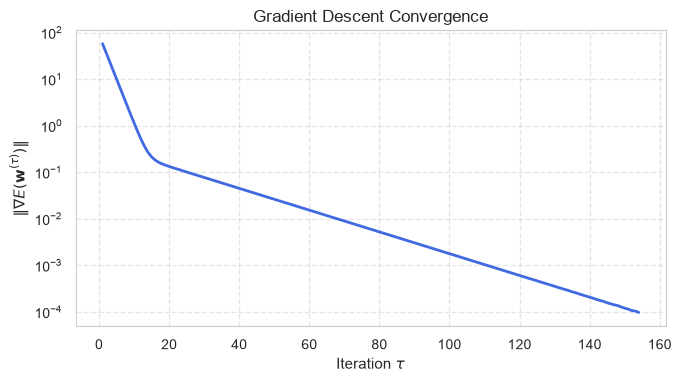

In [27]:
# Solving the overdetermined system by gradient descent and comparing with the pseudo-inverse
# solution w*
w_gd, grad_norms = gradient_descent(X_over, t_obs, torch.zeros((2, 1)), eta=0.05, epsilon=1e-4)
display(Markdown(rf"Stopped after {len(grad_norms) - 1} updates with "
                 rf"$\|\nabla E(\mathbf{{w}})\| = {grad_norms[-1]:.1e} \le \epsilon = 10^{{-4}}$"))
display(Markdown(rf"$\mathbf{{w}}_\mathrm{{GD}} = ({w_gd[0, 0].item():.3f}, "
                 rf"{w_gd[1, 0].item():.3f})^\mathrm{{T}}$ and $\mathbf{{w}}^\star = "
                 rf"({w_star[0, 0].item():.3f}, {w_star[1, 0].item():.3f})^\mathrm{{T}}$"))
hp.plot_convergence(grad_norms)

# Matrix Decompositions and Spectral Theory

- An **eigenvector** of a square matrix $\mathbf{A} \in \mathbb{R}^{M \times M}$ is a non-zero vector $\mathbf{u}$ that $\mathbf{A}$ only scales:
$$\mathbf{A}\mathbf{u} = \lambda \mathbf{u}$$
  where the scalar $\lambda$ is the corresponding **eigenvalue**. For a general real matrix, eigenvalues and eigenvectors may be complex.
- Non-trivial solutions require the **characteristic equation** $\det(\mathbf{A} - \lambda \mathbf{I}) = 0$.
- **Spectral Theorem for Real Symmetric Matrices** ($\mathbf{A} = \mathbf{A}^\mathrm{T}$):
  1. All eigenvalues $\lambda_i$ are **real**.
  2. Eigenvectors can be chosen **orthonormal**: $\mathbf{u}_i^\mathrm{T}\mathbf{u}_j = \delta_{ij}$.
  3. $\mathbf{A}$ factorizes into an orthogonal matrix $\mathbf{U} = (\mathbf{u}_1, \dots, \mathbf{u}_M)$ (a rotation, possibly combined with a reflection) and the diagonal scaling $\boldsymbol{\Lambda} = \mathrm{diag}(\lambda_1, \dots, \lambda_M)$:
$$\mathbf{A} = \mathbf{U}\boldsymbol{\Lambda}\mathbf{U}^\mathrm{T} = \sum_{i=1}^M \lambda_i \mathbf{u}_i \mathbf{u}_i^\mathrm{T}, \qquad \mathbf{U}^\mathrm{T}\mathbf{U} = \mathbf{U}\mathbf{U}^\mathrm{T} = \mathbf{I}$$

<small>📖 *Source: [Bishop, C. M. & Bishop, H. (2024). Deep Learning: Foundations and Concepts. Springer (Appendix A.4)](https://doi.org/10.1007/978-3-031-45468-4)*</small>

In [28]:
# Eigendecomposition of a real symmetric matrix
m_raw = torch.tensor([[1.0, 4.0], [-2.0, 3.0]], dtype=torch.float32)
A_symm = torch.matmul(m_raw, m_raw.t())  # Symmetric: A = A^T

evals_symm, evecs_symm = torch.linalg.eigh(A_symm)
det_U = torch.linalg.det(evecs_symm).item()

In [29]:
display(Markdown(r"Symmetric matrix $\mathbf{A}$:"))
print(A_symm.numpy().round(3))
display(Markdown("Eigenvalues (ascending): " + ", ".join(f"{v:.3f}" for v in evals_symm.tolist())))
display(Markdown(r"Orthonormal eigenvectors (columns of $\mathbf{U}$):"))
print(evecs_symm.numpy().round(3))
kind = "a rotation" if det_U > 0 else "a reflection (combined with a rotation)"
display(Markdown(rf"$\det \mathbf{{U}} = {det_U:+.0f}$: here $\mathbf{{U}}$ is {kind}"))

Symmetric matrix $\mathbf{A}$:

[[17. 10.]
 [10. 13.]]


Eigenvalues (ascending): 4.802, 25.198

Orthonormal eigenvectors (columns of $\mathbf{U}$):

[[ 0.634 -0.773]
 [-0.773 -0.634]]


$\det \mathbf{U} = -1$: here $\mathbf{U}$ is a reflection (combined with a rotation)

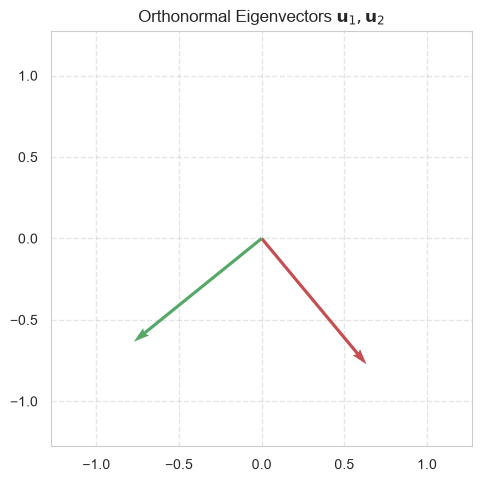

In [30]:
hp.plot2d(evecs_symm, title=r"Orthonormal Eigenvectors $\mathbf{u}_1, \mathbf{u}_2$");

## Quadratic Forms and Positive Definiteness

- A **quadratic form** is a scalar function of vector $\mathbf{x}$:
$$q(\mathbf{x}) = \mathbf{x}^\mathrm{T}\mathbf{A}\mathbf{x} = \sum_{i=1}^M \sum_{j=1}^M A_{ij} x_i x_j$$
- A **symmetric** matrix $\mathbf{A}$ is **positive definite** ($\mathbf{A} \succ 0$) if
$$\mathbf{x}^\mathrm{T}\mathbf{A}\mathbf{x} > 0 \quad \forall \mathbf{x} \neq \mathbf{0} \iff \lambda_i > 0 \quad (i = 1, \dots, M)$$
- and **positive semidefinite** ($\mathbf{A} \succeq 0$) if
$$\mathbf{x}^\mathrm{T}\mathbf{A}\mathbf{x} \ge 0 \quad \forall \mathbf{x} \iff \lambda_i \ge 0 \quad (i = 1, \dots, M)$$
- **Mahalanobis Distance**: For a covariance matrix $\boldsymbol{\Sigma} \succ 0$ and mean $\boldsymbol{\mu}$, the quantity
$$\Delta^2 = (\mathbf{x} - \boldsymbol{\mu})^\mathrm{T}\boldsymbol{\Sigma}^{-1}(\mathbf{x} - \boldsymbol{\mu})$$
  is constant on the ellipsoidal surfaces of constant density of the multivariate Gaussian distribution.

<small>📖 *Source: [Bishop, C. M. & Bishop, H. (2024). Deep Learning: Foundations and Concepts. Springer (Appendix A.4, Section 3.2.1)](https://doi.org/10.1007/978-3-031-45468-4)*</small>

## Curvature, Hessians, and Condition Number

- Near a minimum $\mathbf{w}^\star$, the error surface is described by the **Hessian** $\mathbf{H} = \nabla^2 E(\mathbf{w}^\star)$, the symmetric matrix of second derivatives:
$$E(\mathbf{w}) \approx E(\mathbf{w}^\star) + \frac{1}{2}(\mathbf{w} - \mathbf{w}^\star)^\mathrm{T}\mathbf{H}(\mathbf{w} - \mathbf{w}^\star)$$
- Its eigenvalues $\lambda_i$, defined by $\mathbf{H}\mathbf{u}_i = \lambda_i \mathbf{u}_i$ *(spectral theorem above)*, are the curvatures along its eigenvectors $\mathbf{u}_i$; they are real because $\mathbf{H}$ is symmetric. The **condition number** of a positive-definite Hessian is the ratio of the largest to the smallest curvature:
$$\kappa(\mathbf{H}) = \frac{\lambda_{\max}}{\lambda_{\min}}$$
  Some texts use the square root $(\lambda_{\max}/\lambda_{\min})^{1/2}$ instead; here $\kappa$ is the ratio itself.
- $\kappa \approx 1$: circular contours, the gradient points at the minimum. $\kappa \gg 1$: a long, narrow valley; gradient descent oscillates across the steep direction and creeps along the flat one.
- Rescaling the inputs reduces $\kappa$: standardization removes differences in scale, whitening (below) also removes correlations.
- Convergence of gradient descent and the role of $\kappa$: *(→ Lecture 07_gradient_descent)*.

<small>📖 *Source: [Bishop, C. M. & Bishop, H. (2024). Deep Learning: Foundations and Concepts. Springer (Sections 7.1.1, 7.3)](https://doi.org/10.1007/978-3-031-45468-4)*</small>

In [31]:
# Well- vs ill-conditioned Hessians, and the Hessian H = X^T X of the least-squares example
H_well = torch.tensor([[2.0, 0.0], [0.0, 2.5]], dtype=torch.float32)
H_ill = torch.tensor([[10.0, 0.0], [0.0, 0.2]], dtype=torch.float32)
display(Markdown(r"$\kappa(\mathbf{H}_\mathrm{well}) = "
                 rf"{torch.linalg.cond(H_well).item():.2f}$ (fast, direct convergence), "
                 r"$\kappa(\mathbf{H}_\mathrm{ill}) = "
                 rf"{torch.linalg.cond(H_ill).item():.2f}$ (narrow valley, oscillations)"))

H_ls = torch.matmul(X_over.t(), X_over)                  # Hessian of E(w) = 1/2 ||X w - t||^2
lambda_ls = torch.linalg.eigvalsh(H_ls)                  # ascending: lambda_min, lambda_max
display(Markdown(r"Least-squares example: "
                 r"$\mathbf{H} = \mathbf{X}^\mathrm{T}\mathbf{X}$ has eigenvalues "
                 rf"$\lambda_{{\min}} = {lambda_ls[0].item():.2f}$ and "
                 rf"$\lambda_{{\max}} = {lambda_ls[1].item():.2f}$, "
                 r"so $\kappa = \lambda_{\max} / \lambda_{\min} = "
                 rf"{(lambda_ls[1] / lambda_ls[0]).item():.1f}$: gradient descent above needed "
                 rf"{len(grad_norms) - 1} updates. "
                 r"It converges only for $\eta < 2/\lambda_{\max} = "
                 rf"{(2 / lambda_ls[1]).item():.3f}$ (we used $\eta = 0.05$)."))

$\kappa(\mathbf{H}_\mathrm{well}) = 1.25$ (fast, direct convergence), $\kappa(\mathbf{H}_\mathrm{ill}) = 50.00$ (narrow valley, oscillations)

Least-squares example: $\mathbf{H} = \mathbf{X}^\mathrm{T}\mathbf{X}$ has eigenvalues $\lambda_{\min} = 1.05$ and $\lambda_{\max} = 32.90$, so $\kappa = \lambda_{\max} / \lambda_{\min} = 31.4$: gradient descent above needed 153 updates. It converges only for $\eta < 2/\lambda_{\max} = 0.061$ (we used $\eta = 0.05$).

## Singular Value Decomposition (SVD)

- Eigendecomposition needs a square matrix; the **singular value decomposition** exists for every $\mathbf{A} \in \mathbb{R}^{N \times D}$:
$$\mathbf{A} = \mathbf{U}\boldsymbol{\Sigma}\mathbf{V}^\mathrm{T}$$
  - $\mathbf{U} \in \mathbb{R}^{N \times N}$: orthogonal, columns $\mathbf{u}_i$ are the **left singular vectors** (eigenvectors of $\mathbf{A}\mathbf{A}^\mathrm{T}$)
  - $\boldsymbol{\Sigma} \in \mathbb{R}^{N \times D}$: the **singular-value matrix** (not a covariance matrix), zero except for the singular values $\sigma_1 \ge \sigma_2 \ge \dots \ge 0$ on its diagonal
  - $\mathbf{V} \in \mathbb{R}^{D \times D}$: orthogonal, columns $\mathbf{v}_i$ are the **right singular vectors** (eigenvectors of $\mathbf{A}^\mathrm{T}\mathbf{A}$)
- The non-zero singular values are the square roots of the non-zero eigenvalues of $\mathbf{A}^\mathrm{T}\mathbf{A}$: $\sigma_i = \sqrt{\lambda_i(\mathbf{A}^\mathrm{T}\mathbf{A})}$.
- **Pseudo-inverse via SVD**, also for rank-deficient $\mathbf{A}$: $\mathbf{A}^\dagger = \mathbf{V}\boldsymbol{\Sigma}^\dagger\mathbf{U}^\mathrm{T}$, where $\boldsymbol{\Sigma}^\dagger \in \mathbb{R}^{D \times N}$ is $\boldsymbol{\Sigma}^\mathrm{T}$ with every non-zero $\sigma_i$ replaced by $1/\sigma_i$.
- In PCA (below), the right singular vectors of the centred data matrix are the principal directions.

<small>📖 *Source: [Bishop, C. M. & Bishop, H. (2024). Deep Learning: Foundations and Concepts. Springer (Section 4.1.4)](https://doi.org/10.1007/978-3-031-45468-4)*</small>

## Low-Rank Approximation (Eckart–Young–Mirsky)

- Keeping only the $M$ largest singular values gives the **truncated SVD**
$$\mathbf{A}_M = \sum_{i=1}^M \sigma_i \mathbf{u}_i \mathbf{v}_i^\mathrm{T} = \mathbf{U}_M \boldsymbol{\Sigma}_M \mathbf{V}_M^\mathrm{T}$$
  where $\mathbf{U}_M$, $\mathbf{V}_M$ hold the first $M$ singular vectors and $\boldsymbol{\Sigma}_M = \mathrm{diag}(\sigma_1, \dots, \sigma_M)$.
- **Eckart–Young–Mirsky theorem**: no matrix of rank at most $M$ is closer to $\mathbf{A}$, in the Frobenius norm $\|\cdot\|_\mathrm{F}$ and in the spectral norm $\|\cdot\|_2$ *(definitions → Appendix A1)*. The errors are
$$\|\mathbf{A} - \mathbf{A}_M\|_\mathrm{F} = \sqrt{\textstyle\sum_{i > M} \sigma_i^2}, \qquad \|\mathbf{A} - \mathbf{A}_M\|_2 = \sigma_{M+1}$$
- Applications: image compression (end of this lecture) and low-rank weight updates for fine-tuning large language models *(→ Lecture 12_transformers)*.

<small>📖 *Source: [Eckart, C. & Young, G. (1936). The approximation of one matrix by another of lower rank. Psychometrika, 1(3), 211–218](https://doi.org/10.1007/BF02288367)*</small>

In [32]:
# Truncated SVD: the best rank-M approximation, checked on a random matrix
def low_rank_approximation(U, sigma, V_T, M):
    """Rank-M truncated SVD U_M diag(sigma_1, ..., sigma_M) V_M^T from a thin SVD (U, sigma,
    V^T)."""
    return U[:, :M] @ torch.diag(sigma[:M]) @ V_T[:M, :]

torch.manual_seed(0)
A_lr = torch.randn(6, 4)
U_lr, sigma_lr, V_T_lr = torch.linalg.svd(A_lr, full_matrices=False)
display(Markdown("Singular values: " + ", ".join(f"{s:.3f}" for s in sigma_lr.tolist())))
for M in (1, 2, 3):
    A_M = low_rank_approximation(U_lr, sigma_lr, V_T_lr, M)
    error_F = torch.linalg.matrix_norm(A_lr - A_M).item()
    display(Markdown(rf"$M = {M}$: $\|\mathbf{{A}} - \mathbf{{A}}_M\|_\mathrm{{F}} = "
                     rf"{error_F:.4f}$ and $\sqrt{{\sum_{{i > M}} \sigma_i^2}} = "
                     rf"{sigma_lr[M:].square().sum().sqrt().item():.4f}$"))

Singular values: 3.523, 3.121, 1.529, 0.674

$M = 1$: $\|\mathbf{A} - \mathbf{A}_M\|_\mathrm{F} = 3.5405$ and $\sqrt{\sum_{i > M} \sigma_i^2} = 3.5405$

$M = 2$: $\|\mathbf{A} - \mathbf{A}_M\|_\mathrm{F} = 1.6713$ and $\sqrt{\sum_{i > M} \sigma_i^2} = 1.6713$

$M = 3$: $\|\mathbf{A} - \mathbf{A}_M\|_\mathrm{F} = 0.6742$ and $\sqrt{\sum_{i > M} \sigma_i^2} = 0.6742$

# Principal Component Analysis (PCA)

- PCA is the standard linear technique for dimensionality reduction, lossy data compression, feature extraction and visualization.
- Data: $N$ observations $\mathbf{x}_n \in \mathbb{R}^D$, centred to zero mean, $\frac{1}{N}\sum_{n=1}^N \mathbf{x}_n = \mathbf{0}$ (subtract the sample mean first); they form the rows of $\mathbf{X} \in \mathbb{R}^{N \times D}$.
- **Two equivalent formulations** of the projection onto an $M$-dimensional subspace ($M < D$):
  1. **Maximum variance**: maximize the variance of the projected data.
  2. **Minimum reconstruction error**: minimize the mean squared distance between the data points and their projections.
- Both give the same solution: the eigenvectors of the data covariance matrix $\mathbf{S}$ that belong to its $M$ largest eigenvalues.

<small>📖 *Source: [Bishop, C. M. & Bishop, H. (2024). Deep Learning: Foundations and Concepts. Springer (Section 16.1)](https://doi.org/10.1007/978-3-031-45468-4)*</small>

## Maximum Variance Formulation

- We seek a unit direction $\mathbf{u}_1 \in \mathbb{R}^D$ ($\mathbf{u}_1^\mathrm{T}\mathbf{u}_1 = 1$) such that projecting the centered data points $\mathbf{x}_n$ onto $\mathbf{u}_1$ maximizes the projected sample variance:
$$\frac{1}{N}\sum_{n=1}^N (\mathbf{u}_1^\mathrm{T}\mathbf{x}_n)^2 = \mathbf{u}_1^\mathrm{T}\mathbf{S}\mathbf{u}_1$$
  where $\mathbf{S} = \frac{1}{N}\sum_{n=1}^N \mathbf{x}_n \mathbf{x}_n^\mathrm{T} = \frac{1}{N}\mathbf{X}^\mathrm{T}\mathbf{X}$ is the **sample covariance matrix**.
- Enforcing the normalization constraint $\mathbf{u}_1^\mathrm{T}\mathbf{u}_1 = 1$ via a Lagrange multiplier $\lambda_1$:
$$\mathcal{L}(\mathbf{u}_1, \lambda_1) = \mathbf{u}_1^\mathrm{T}\mathbf{S}\mathbf{u}_1 - \lambda_1(\mathbf{u}_1^\mathrm{T}\mathbf{u}_1 - 1)$$
- Setting the gradient with respect to $\mathbf{u}_1$ to zero yields the **eigenvalue equation**:
$$\mathbf{S}\mathbf{u}_1 = \lambda_1 \mathbf{u}_1$$
- The maximum variance is equal to the largest eigenvalue: $\mathbf{u}_1^\mathrm{T}\mathbf{S}\mathbf{u}_1 = \lambda_1$.
- Subsequent components $\mathbf{u}_2, \dots, \mathbf{u}_M$ correspond to the remaining eigenvectors in descending order of eigenvalues.

<small>📖 *Source: [Bishop, C. M. & Bishop, H. (2024). Deep Learning: Foundations and Concepts. Springer (Section 16.1.1, Appendix C)](https://doi.org/10.1007/978-3-031-45468-4)*</small>

## Minimum Reconstruction Error Formulation

- Consider an orthonormal basis $\{\mathbf{u}_i\}_{i=1}^D$. Each data vector can be represented exactly as:
$$\mathbf{x}_n = \sum_{i=1}^D (\mathbf{x}_n^\mathrm{T}\mathbf{u}_i) \mathbf{u}_i$$
- Approximating each data point by an $M$-dimensional principal subspace ($M < D$):
$$\tilde{\mathbf{x}}_n = \sum_{i=1}^M (\mathbf{x}_n^\mathrm{T}\mathbf{u}_i) \mathbf{u}_i$$
- The objective is to minimize the sum-of-squares reconstruction distortion:
$$J = \frac{1}{N}\sum_{n=1}^N \|\mathbf{x}_n - \tilde{\mathbf{x}}_n\|^2 = \sum_{i=M+1}^D \mathbf{u}_i^\mathrm{T}\mathbf{S}\mathbf{u}_i$$
- Minimizing $J$ subject to $\mathbf{u}_i^\mathrm{T}\mathbf{u}_j = \delta_{ij}$ requires choosing $\mathbf{u}_i$ to be the eigenvectors of $\mathbf{S}$.
- **The reconstruction distortion equals the sum of the discarded eigenvalues**:
$$J = \sum_{i=M+1}^D \lambda_i$$

<small>📖 *Source: [Bishop, C. M. & Bishop, H. (2024). Deep Learning: Foundations and Concepts. Springer (Section 16.1.2)](https://doi.org/10.1007/978-3-031-45468-4)*</small>


## Data Whitening (Sphering)

- PCA transforms correlated inputs into uncorrelated coordinates with **identity covariance**.
- With the eigendecomposition $\mathbf{S} = \mathbf{U}\boldsymbol{\Lambda}\mathbf{U}^\mathrm{T}$ of the covariance matrix, define the **whitened coordinates**
$$\mathbf{y}_n = \boldsymbol{\Lambda}^{-1/2}\mathbf{U}^\mathrm{T}\mathbf{x}_n$$
- Their covariance is the identity:
$$
\begin{aligned}
\mathrm{cov}[\mathbf{y}] &= \frac{1}{N}\sum_{n=1}^N \mathbf{y}_n \mathbf{y}_n^\mathrm{T} = \boldsymbol{\Lambda}^{-1/2}\mathbf{U}^\mathrm{T}\mathbf{S}\mathbf{U}\boldsymbol{\Lambda}^{-1/2} \\
&= \boldsymbol{\Lambda}^{-1/2}\boldsymbol{\Lambda}\boldsymbol{\Lambda}^{-1/2} = \mathbf{I}
\end{aligned}
$$
- **Geometric effect**: whitening rotates the data onto the principal axes and scales axis $i$ by $1/\sqrt{\lambda_i}$, turning elongated density ellipses into circles.

<small>📖 *Source: [Bishop, C. M. & Bishop, H. (2024). Deep Learning: Foundations and Concepts. Springer (Section 16.1.4, Figure 16.6)](https://doi.org/10.1007/978-3-031-45468-4)*</small>

In [33]:
# Demonstration of data whitening on correlated synthetic data
torch.manual_seed(42)
N_samples = 400
Z_raw = torch.randn(N_samples, 2)
mix_op = torch.tensor([[2.0, 1.2], [0.4, 1.0]])
X_synth = torch.matmul(Z_raw, mix_op.t())
X_cent = X_synth - X_synth.mean(dim=0, keepdim=True)      # centred data

S_synth = torch.matmul(X_cent.t(), X_cent) / N_samples
e_vals, e_vecs = torch.linalg.eigh(S_synth)

# Whitening transformation y_n = Lambda^{-1/2} U^T x_n (all rows at once)
Y_white = torch.matmul(torch.matmul(X_cent, e_vecs), torch.diag(1.0 / torch.sqrt(e_vals)))
cov_white = torch.matmul(Y_white.t(), Y_white) / N_samples

display(Markdown(r"Covariance matrix $\mathbf{S}$ of the centred data:"))
print(S_synth.numpy().round(3))
display(Markdown(r"Covariance matrix of the whitened data (the identity $\mathbf{I}$):"))
print(cov_white.numpy().round(3) + 0.0)

Covariance matrix $\mathbf{S}$ of the centred data:

[[5.686 2.187]
 [2.187 1.243]]


Covariance matrix of the whitened data (the identity $\mathbf{I}$):

[[1. 0.]
 [0. 1.]]


## PCA for High-Dimensional Data ($N < D$)

- For e.g. $N = 100$ images with $D = 10{,}000$ pixels, $\mathbf{S} = \frac{1}{N}\mathbf{X}^\mathrm{T}\mathbf{X}$ is $D \times D$: its eigendecomposition costs $\mathcal{O}(D^3) \approx 10^{12}$ operations.
- At most $N - 1$ eigenvalues are non-zero, so we can solve the eigenvalue problem of the $N \times N$ matrix $\frac{1}{N}\mathbf{X}\mathbf{X}^\mathrm{T}$ instead:
$$\frac{1}{N}\mathbf{X}\mathbf{X}^\mathrm{T}\mathbf{v}_i = \lambda_i \mathbf{v}_i$$
- Multiplying both sides by $\mathbf{X}^\mathrm{T}$:
$$\left( \frac{1}{N}\mathbf{X}^\mathrm{T}\mathbf{X} \right) (\mathbf{X}^\mathrm{T}\mathbf{v}_i) = \lambda_i (\mathbf{X}^\mathrm{T}\mathbf{v}_i)$$
- So $\mathbf{X}^\mathrm{T}\mathbf{v}_i$ is an eigenvector of $\mathbf{S}$ with the same eigenvalue; for $\|\mathbf{v}_i\| = 1$ the unit eigenvector is $\mathbf{u}_i = (N\lambda_i)^{-1/2}\mathbf{X}^\mathrm{T}\mathbf{v}_i$.
- The cost drops from $\mathcal{O}(D^3)$ to $\mathcal{O}(N^3)$. The SVD of $\mathbf{X}$ (next slide) gives both sets of eigenvectors at once.

<small>📖 *Source: [Bishop, C. M. & Bishop, H. (2024). Deep Learning: Foundations and Concepts. Springer (Section 16.1.5)](https://doi.org/10.1007/978-3-031-45468-4)*</small>

## Computing PCA with the SVD

- Write the thin SVD of the centred data matrix as
$$\mathbf{X} = \mathbf{L}\boldsymbol{\Sigma}\mathbf{U}^\mathrm{T}$$
  with $\boldsymbol{\Sigma} = \mathrm{diag}(\sigma_1, \dots, \sigma_D)$. We name the right singular vectors $\mathbf{U}$ because they are the principal directions; $\mathbf{L}$ holds the left singular vectors (the $\mathbf{v}_i$ of the previous slide).
- Then the covariance matrix is already diagonalized:
$$\mathbf{S} = \frac{1}{N}\mathbf{X}^\mathrm{T}\mathbf{X} = \mathbf{U}\,\frac{\boldsymbol{\Sigma}^2}{N}\,\mathbf{U}^\mathrm{T}$$
  - **principal directions** $\mathbf{u}_i$: the columns of $\mathbf{U}$ (right singular vectors),
  - **eigenvalues** $\lambda_i = \sigma_i^2 / N$ (variance along $\mathbf{u}_i$),
  - **scores** $z_{ni} = \mathbf{u}_i^\mathrm{T}\mathbf{x}_n$, i.e. $\mathbf{Z} = \mathbf{X}\mathbf{U} = \mathbf{L}\boldsymbol{\Sigma}$.
- The SVD avoids forming $\mathbf{X}^\mathrm{T}\mathbf{X}$, which squares the condition number.

In [34]:
# PCA of a centred (or standardized) data matrix via the thin SVD X = L Sigma U^T
def pca_svd(X):
    """PCA of a data matrix X (N x D) whose columns are already centred or standardized.

    Returns the scores Z = X U (N x K), the principal directions U (D x K, column i is u_i)
    and the eigenvalues lambda_i = sigma_i^2 / N of S = X^T X / N in decreasing order, K =
    min(N, D).
    """
    L, sigma, U_T = torch.linalg.svd(X, full_matrices=False)
    U = U_T.t()
    return torch.matmul(X, U), U, sigma ** 2 / X.shape[0]

# Check against the eigendecomposition of S for the centred synthetic data above (eigh sorts
# ascending)
Z_synth, U_synth, lambda_synth = pca_svd(X_cent)
display(Markdown(rf"SVD: $\lambda_1 = {lambda_synth[0].item():.3f}$, $\lambda_2 = "
                 rf"{lambda_synth[1].item():.3f}$, $\mathbf{{u}}_1 = "
                 rf"({U_synth[0, 0].item():.3f}, {U_synth[1, 0].item():.3f})^\mathrm{{T}}$"))
display(Markdown(r"Eigendecomposition of $\mathbf{S}$: $\lambda_1 = "
                 rf"{e_vals[1].item():.3f}$, $\lambda_2 = {e_vals[0].item():.3f}$, "
                 rf"$\mathbf{{u}}_1 = ({e_vecs[0, 1].item():.3f}, "
                 rf"{e_vecs[1, 1].item():.3f})^\mathrm{{T}}$ (equal up to the sign)"))

SVD: $\lambda_1 = 6.582$, $\lambda_2 = 0.347$, $\mathbf{u}_1 = (-0.925, -0.379)^\mathrm{T}$

Eigendecomposition of $\mathbf{S}$: $\lambda_1 = 6.582$, $\lambda_2 = 0.347$, $\mathbf{u}_1 = (-0.925, -0.379)^\mathrm{T}$ (equal up to the sign)

## Case Study: US Arrests Dataset

- Statistics for each of the 50 US states in 1973 ($N = 50$ observations, $D = 4$ features):
  - `Assault`, `Murder`, `Rape`: Arrests per 100,000 residents
  - `UrbanPop`: Percentage of the population living in urban areas


In [35]:
us = pd.read_csv(hp.get_file("USArrests.csv"))
states = us.pop(us.columns[0])
us.head()

,Murder,Assault,UrbanPop,Rape
0,13.2,236,58,21.2
1,10.0,263,48,44.5
2,8.1,294,80,31.0
3,8.8,190,50,19.5
4,9.0,276,91,40.6


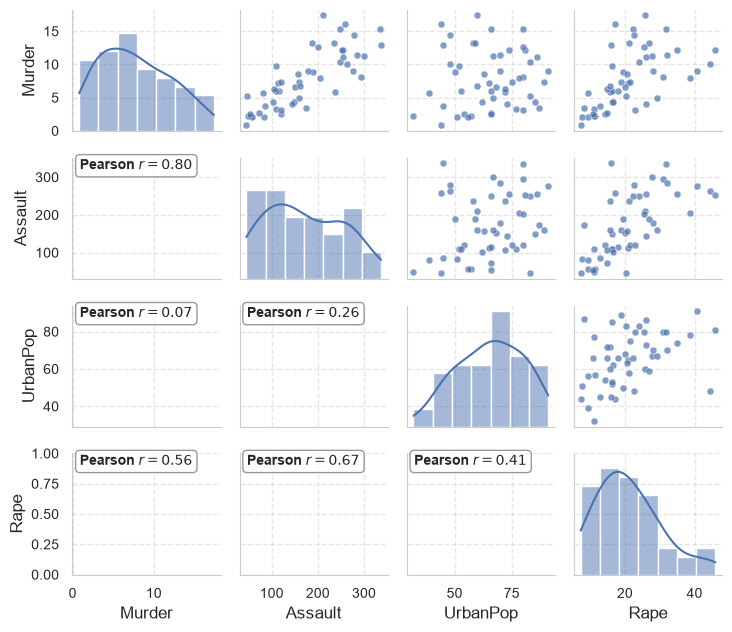

In [36]:
hp.plot_pairgrid(us);

In [37]:
us.describe()


,Murder,Assault,UrbanPop,Rape
count,50.00000,50.000000,50.000000,50.000000
mean,7.78800,170.760000,65.540000,21.232000
std,4.35551,83.337661,14.474763,9.366385
min,0.80000,45.000000,32.000000,7.300000
25%,4.07500,109.000000,54.500000,15.075000
50%,7.25000,159.000000,66.000000,20.100000
75%,11.25000,249.000000,77.750000,26.175000
max,17.40000,337.000000,91.000000,46.000000


## Data Standardization and the Correlation Matrix

- The features have different units and variances (`Assault` varies far more than `Murder`); PCA on the raw data would be dominated by `Assault`. We **standardize** each feature $i$:
$$x'_{ni} = \frac{x_{ni} - \bar{x}_i}{\sigma_i}, \qquad \bar{x}_i = \frac{1}{N}\sum_{n=1}^N x_{ni}$$
$$\sigma_i^2 = \frac{1}{N}\sum_{n=1}^N (x_{ni} - \bar{x}_i)^2$$
- The covariance matrix $\mathbf{S}$ of the standardized data (normalized by $\frac{1}{N}$ as in PCA) is the **correlation matrix** of the original features:
$$S_{ij} = \frac{1}{N}\sum_{n=1}^N x'_{ni} x'_{nj} = \rho_{ij}$$
  where $\rho_{ij} \in [-1, 1]$ is the correlation of features $i$ and $j$, and $S_{ii} = 1$.
- PCA on standardized data is therefore the eigendecomposition of the correlation matrix; its eigenvalues sum to $\mathrm{Tr}(\mathbf{S}) = D$.

> 📝 **Note:** Many libraries (e.g. pandas) divide by $N - 1$ instead of $N$. Used in both $\sigma_i$ and $\mathbf{S}$, the factor cancels: the correlation matrix and the principal directions do not change.

<small>📖 *Source: [Bishop, C. M. & Bishop, H. (2024). Deep Learning: Foundations and Concepts. Springer (Section 16.1.4)](https://doi.org/10.1007/978-3-031-45468-4)*</small>

In [38]:
# Feature standardization with the 1/N normalization (zero mean, unit variance)
def standardize(T: torch.Tensor) -> torch.Tensor:
    """Standardize each column of T to zero mean and unit variance (variance normalized by 1/N)."""
    means = T.mean(dim=0, keepdim=True)
    stds = T.std(dim=0, correction=0, keepdim=True)
    return (T - means) / stds

T_us = torch.tensor(us.values, dtype=torch.float32)
X_us = standardize(T_us)[:, [0, 1]]                         # Murder and Assault
S_us = torch.matmul(X_us.t(), X_us) / X_us.shape[0]         # covariance of the standardized data

display(Markdown(r"Means and variances of the standardized `Murder` and `Assault` columns:"))
print(X_us.mean(dim=0).numpy().round(3) + 0.0, X_us.var(dim=0, correction=0).numpy().round(3))
display(Markdown(r"Covariance matrix $\mathbf{S}$ of the standardized data (the correlation "
                 r"matrix):"))
print(S_us.numpy().round(3))

Means and variances of the standardized `Murder` and `Assault` columns:

[0. 0.] [1. 1.]


Covariance matrix $\mathbf{S}$ of the standardized data (the correlation matrix):

[[1.    0.802]
 [0.802 1.   ]]


## Projecting the Data onto a Direction

- A unit vector $\mathbf{u} = (\cos\theta, \sin\theta)^\mathrm{T}$ defines a line through the origin. The **orthogonal projection** of $\mathbf{x}_n$ onto it is $\mathbf{u}\mathbf{u}^\mathrm{T}\mathbf{x}_n$; for all rows at once $\mathbf{X}\mathbf{P}$, with the projection matrix $\mathbf{P} = \mathbf{u}\mathbf{u}^\mathrm{T}$ (since $\mathbf{u}^\mathrm{T}\mathbf{u} = 1$).
- The projected coordinates $\mathbf{u}^\mathrm{T}\mathbf{x}_n$ have variance $\mathbf{u}^\mathrm{T}\mathbf{S}\mathbf{u}$: the quantity that PCA maximizes.
- Turn the angle $\theta$: where is $\mathbf{u}^\mathrm{T}\mathbf{S}\mathbf{u}$ largest, and how long are the drop lines there?

In [39]:
def project_onto_direction(theta=0):
    # unit direction
    u = torch.tensor([math.cos(math.radians(theta)), math.sin(math.radians(theta))])
    # X P with P = u u^T
    X_proj = torch.matmul(X_us, torch.outer(u, u))
    display(Markdown(rf"$\theta = {theta}^\circ$: projected variance "
                     r"$\mathbf{u}^\mathrm{T}\mathbf{S}\mathbf{u} = "
                     rf"{(u @ S_us @ u).item():.3f}$"))
    hp.plot_projection(X_us, X_proj, u, xlabel="Murder (standardized)",
                       ylabel="Assault (standardized)")

In [40]:
interact(project_onto_direction, theta=(0, 180, 5));

interactive(children=(IntSlider(value=0, description='theta', max=180, step=5), Output()), _dom_classes=('widg…

In [41]:
# PCA of the two standardized features
Z_us, U_us, lambda_us = pca_svd(X_us)
for i in range(2):
    display(Markdown(rf"$\mathbf{{u}}_{i + 1} = ({U_us[0, i].item():.3f}, "
                     rf"{U_us[1, i].item():.3f})^\mathrm{{T}}$, $\lambda_{i + 1} = "
                     rf"{lambda_us[i].item():.3f}$"))
display(Markdown(r"The widget reaches the maximum "
                 r"$\mathbf{u}^\mathrm{T}\mathbf{S}\mathbf{u} = \lambda_1$ at "
                 r"$\theta = 45^\circ$, where $\mathbf{u} = -\mathbf{u}_1$ spans the same line "
                 r"as $\mathbf{u}_1$."))

$\mathbf{u}_1 = (-0.707, -0.707)^\mathrm{T}$, $\lambda_1 = 1.802$

$\mathbf{u}_2 = (0.707, -0.707)^\mathrm{T}$, $\lambda_2 = 0.198$

The widget reaches the maximum $\mathbf{u}^\mathrm{T}\mathbf{S}\mathbf{u} = \lambda_1$ at $\theta = 45^\circ$, where $\mathbf{u} = -\mathbf{u}_1$ spans the same line as $\mathbf{u}_1$.

### Loading Vectors

- The unit direction $\mathbf{u}_i$ is also called the **loading vector** of component $i$; its entries $u_{1i}, \dots, u_{Di}$ are the **loadings** of the $D$ features.
- The **score** of observation $n$ on component $i$ is its projected coordinate $z_{ni} = \mathbf{u}_i^\mathrm{T}\mathbf{x}_n$; the scores of component $i$ have variance $\lambda_i$.
- The plot shows the arrows $\sqrt{\lambda_i}\,\mathbf{u}_i$: each loading vector stretched by the standard deviation $\sqrt{\lambda_i}$ of its scores. For standardized data, the entries of $\sqrt{\lambda_i}\,\mathbf{u}_i$ are the correlations between the features and the scores of component $i$.

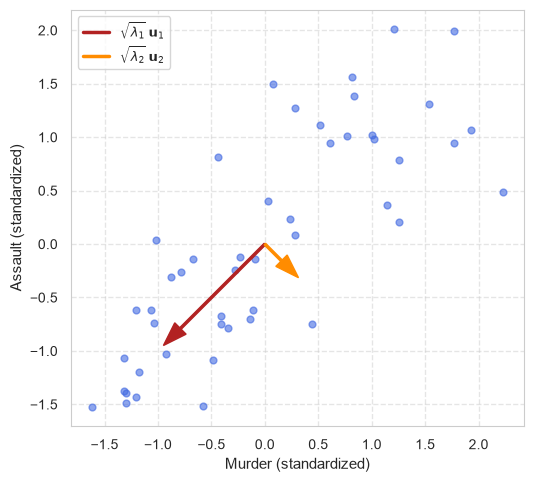

In [42]:
hp.plot_directions(X_us, {r"$\sqrt{\lambda_1}\,\mathbf{u}_1$": lambda_us[0].sqrt() * U_us[:, 0],
                          r"$\sqrt{\lambda_2}\,\mathbf{u}_2$": lambda_us[1].sqrt() * U_us[:, 1]},
                   xlabel="Murder (standardized)", ylabel="Assault (standardized)")

## Case Study: US Arrests (All Four Features)

- PCA of all $D = 4$ standardized features gives four loading vectors $\mathbf{u}_1, \dots, \mathbf{u}_4$ and eigenvalues $\lambda_1 \ge \dots \ge \lambda_4$.
- The **explained-variance ratio** of component $i$ is its share of the total variance:
$$\frac{\lambda_i}{\sum_{j=1}^D \lambda_j}$$
- Keeping $M$ components leaves the reconstruction error $J = \sum_{i=M+1}^D \lambda_i$ (minimum-error formulation).

In [43]:
X_full = standardize(T_us)
Z_f, U_f, lambda_f = pca_svd(X_full)
columns_text = ", ".join(us.columns)
eigenvalues_text = ", ".join(f"{v:.3f}" for v in lambda_f.tolist())
display(Markdown(rf"$\mathbf{{u}}_1 = {hp.format_vector(U_f[:, 0], digits=3)}$ "
                 f"for ({columns_text})"))
display(Markdown(rf"Eigenvalues $\lambda_i$: {eigenvalues_text}, "
                 rf"sum {lambda_f.sum().item():.3f} $= D$"))

$\mathbf{u}_1 = (-0.536, -0.583, -0.278, -0.543)^\mathrm{T}$ for (Murder, Assault, UrbanPop, Rape)

Eigenvalues $\lambda_i$: 2.480, 0.990, 0.357, 0.173, sum 4.000 $= D$

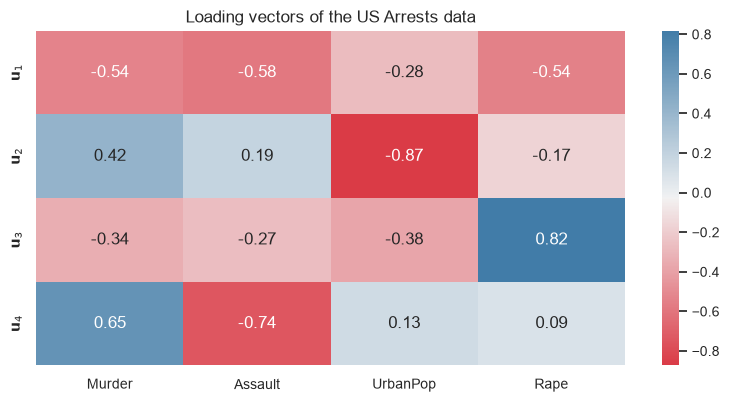

In [44]:
# Loading vectors of all four components (one row per u_i)
hp.plot_loading_heatmap(U_f.t(), x_labels=list(us.columns),
                        y_labels=[rf"$\mathbf{{u}}_{i + 1}$" for i in range(4)],
                        title="Loading vectors of the US Arrests data")

In [45]:
# Explained-variance ratios, their cumulative sums, and the reconstruction error for M = 2
ratio_f = lambda_f / lambda_f.sum()
cumulative_f = torch.cumsum(ratio_f, dim=0)
ratios_text = ", ".join(f"{100 * r:.1f}%" for r in ratio_f.tolist())
cumulative_text = ", ".join(f"{100 * c:.1f}%" for c in cumulative_f.tolist())
display(Markdown(f"Explained-variance ratios: {ratios_text}; cumulative: {cumulative_text}"))

M = 2
# reconstructions from M components
X_rec = torch.matmul(Z_f[:, :M], U_f[:, :M].t())
J_direct = ((X_full - X_rec) ** 2).sum(dim=1).mean().item()
display(Markdown(rf"$M = {M}$: $J = \frac{{1}}{{N}}\sum_n \|\mathbf{{x}}_n - "
                 rf"\tilde{{\mathbf{{x}}}}_n\|^2 = {J_direct:.3f}$ and $\lambda_3 + \lambda_4 "
                 rf"= {lambda_f[M:].sum().item():.3f}$"))

Explained-variance ratios: 62.0%, 24.7%, 8.9%, 4.3%; cumulative: 62.0%, 86.8%, 95.7%, 100.0%

$M = 2$: $J = \frac{1}{N}\sum_n \|\mathbf{x}_n - \tilde{\mathbf{x}}_n\|^2 = 0.530$ and $\lambda_3 + \lambda_4 = 0.530$

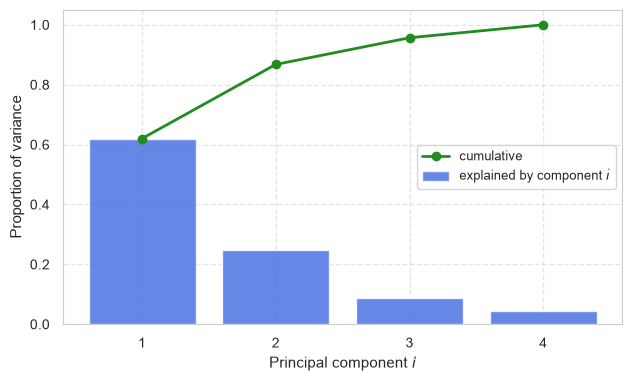

In [46]:
hp.plot_explained_variance(ratio_f, cumulative_f)

## The Biplot Display

- A **biplot** shows, in the plane of components 1 and 2:
  1. the **scores** $(z_{n1}, z_{n2})$ of each observation, with $z_{ni} = \mathbf{u}_i^\mathrm{T}\mathbf{x}_n$;
  2. one arrow per feature $d$, pointing to its loadings $(u_{d1}, u_{d2})$, rescaled to the range of the scores.
- Observations far out along a feature's arrow have high values of that feature.

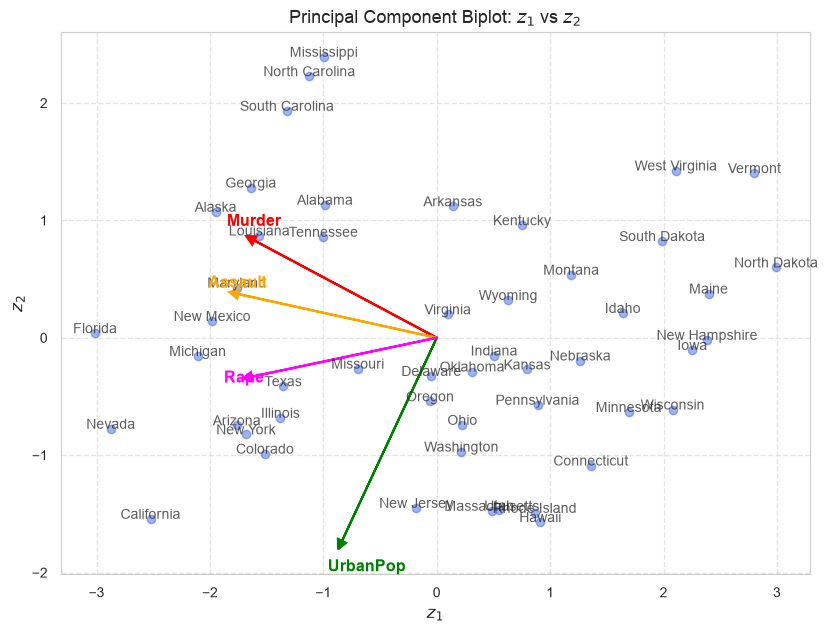

In [47]:
z1, z2 = 0, 1
hp.plot_pca_biplot(z1, z2, Z_f, U_f.t(), states.values, us.columns,
                   colors=['red', 'orange', 'green', 'magenta'], figsize=(8.5, 6.5))

## Case Study: Iris Dataset

- $N = 150$ iris flowers across 3 species (*setosa*, *versicolor*, *virginica*).
- $D = 4$ morphological features: sepal length, sepal width, petal length, petal width.

<center>
    <img src="https://raw.githubusercontent.com/konstantin-schekotihin/dl_course/master/shared/images/iris.png" width="40%"/>
</center>


Iris dataset shape: (150, 5), species: ['setosa', 'versicolor', 'virginica']


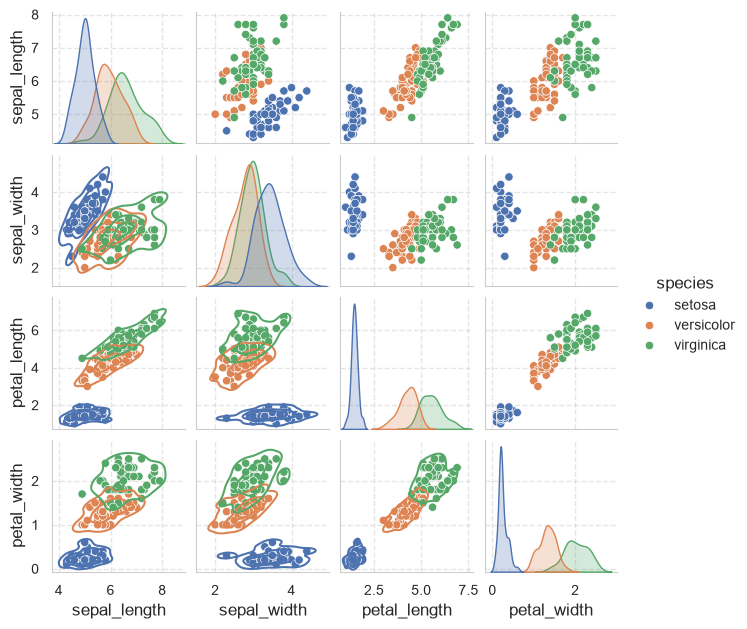

In [48]:
# Load and inspect benchmark Iris dataset
dfi = sns.load_dataset("iris")
print(f"Iris dataset shape: {dfi.shape}, species: {list(dfi['species'].unique())}")
hp.plot_iris_pairplot(dfi, height=1.6)

In [49]:
X_iris = standardize(torch.tensor(dfi.iloc[:, 0:4].values, dtype=torch.float32))
Z_iris, U_iris, lambda_iris = pca_svd(X_iris)
ratio_iris = lambda_iris / lambda_iris.sum()
columns_text = ", ".join(dfi.columns[0:4])
ratios_text = ", ".join(f"{100 * r:.1f}%" for r in ratio_iris.tolist())
display(Markdown(rf"$\mathbf{{u}}_1 = {hp.format_vector(U_iris[:, 0], digits=3)}$ "
                 f"for ({columns_text})"))
display(Markdown(f"Explained-variance ratios: {ratios_text}"))

$\mathbf{u}_1 = (0.521, -0.269, 0.58, 0.565)^\mathrm{T}$ for (sepal_length, sepal_width, petal_length, petal_width)

Explained-variance ratios: 73.0%, 22.9%, 3.7%, 0.5%

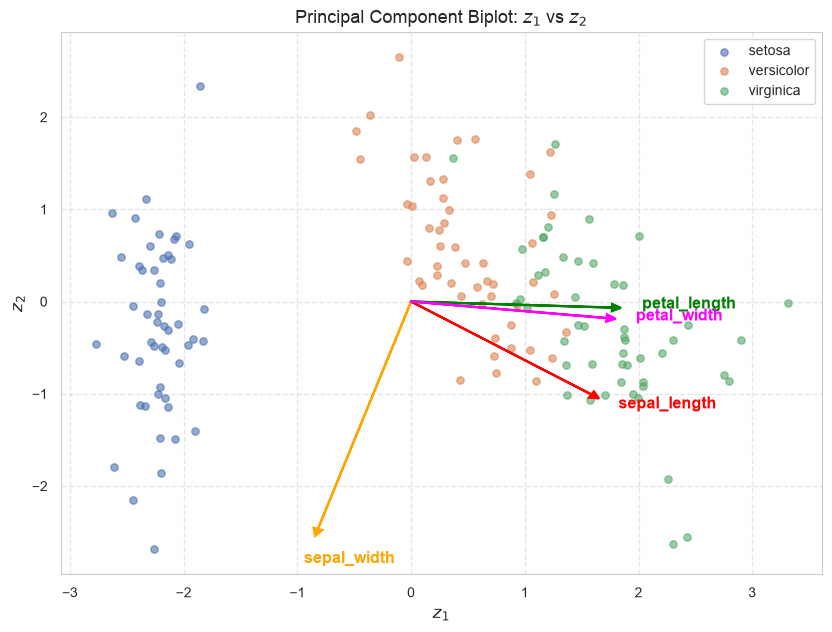

In [50]:
hp.plot_pca_biplot(0, 1, Z_iris, U_iris.t(), None, dfi.columns[0:4],
                   colors=['red', 'orange', 'green', 'magenta'], groups=dfi["species"],
                   figsize=(8.5, 6.5))

> 💡 **Key Takeaway:** PCA never sees the species labels, yet the scores $z_{n1}$ on the first component separate *setosa* from the other two species: $\mathbf{u}_1$ is dominated by the petal measurements, and *setosa* flowers have much smaller petals.

## Case Study: Image Compression with the Truncated SVD

- A colour image of $H \times W$ pixels consists of three matrices $\mathbf{I}_c \in \mathbb{R}^{H \times W}$, one per channel (red, green, blue), with values in $[0, 1]$.
- Replacing each channel by its truncated SVD, the best rank-$M$ approximation,
$$\tilde{\mathbf{I}}_c = \sum_{i=1}^M \sigma_i \mathbf{u}_i \mathbf{v}_i^\mathrm{T}$$
  needs $M(H + W + 1)$ numbers per channel instead of $HW$.
- The kept share of the squared Frobenius norm, $\sum_{i=1}^M \sigma_i^2 / \sum_i \sigma_i^2$, plays the role of the explained-variance ratio. It is not a variance, because the pixel columns are not centred.
- PCA proper compresses a whole *data set* of images, with one eigen-image per component.

<small>📖 *Source: [Bishop, C. M. & Bishop, H. (2024). Deep Learning: Foundations and Concepts. Springer (Section 16.1.3)](https://doi.org/10.1007/978-3-031-45468-4)*</small>

In [51]:
# Load the image as floats in [0, 1] and compute the SVD of each colour channel once
img = torch.tensor(mpimg.imread(hp.get_file("puppy.jpeg")) / 255.0, dtype=torch.float32)
H, W, _ = img.shape
channel_svds = [torch.linalg.svd(img[:, :, c], full_matrices=False) for c in range(3)]

display(Markdown(rf"Image of $H \times W = {H} \times {W}$ pixels with 3 colour channels"))
for M in (5, 20, 50, 100):
    kept = [(svd.S[:M].square().sum() / svd.S.square().sum()).item() for svd in channel_svds]
    display(Markdown(rf"$M = {M}$: kept share of $\|\mathbf{{I}}_c\|_\mathrm{{F}}^2$ (red, "
                     r"green, blue) "
                     + ", ".join(f"{100 * k:.1f}%" for k in kept)
                     + rf"; storage $M(H + W + 1)/(HW)$ = {M * (H + W + 1) / (H * W):.3f}"))

Image of $H \times W = 320 \times 400$ pixels with 3 colour channels

$M = 5$: kept share of $\|\mathbf{I}_c\|_\mathrm{F}^2$ (red, green, blue) 95.7%, 94.4%, 92.3%; storage $M(H + W + 1)/(HW)$ = 0.028

$M = 20$: kept share of $\|\mathbf{I}_c\|_\mathrm{F}^2$ (red, green, blue) 99.4%, 99.3%, 99.0%; storage $M(H + W + 1)/(HW)$ = 0.113

$M = 50$: kept share of $\|\mathbf{I}_c\|_\mathrm{F}^2$ (red, green, blue) 99.9%, 99.9%, 99.8%; storage $M(H + W + 1)/(HW)$ = 0.282

$M = 100$: kept share of $\|\mathbf{I}_c\|_\mathrm{F}^2$ (red, green, blue) 100.0%, 100.0%, 100.0%; storage $M(H + W + 1)/(HW)$ = 0.563

In [52]:
@interact(M=(5, 100, 5))
def show_compression(M=20):
    img_M = torch.stack([low_rank_approximation(svd.U, svd.S, svd.Vh, M) for svd in channel_svds],
                        dim=-1).clamp(0, 1)
    hp.plot_image_grid(torch.stack([img, img_M]),
                       titles=["Original", f"Rank $M = {M}$ per channel"], n_cols=2,
                       figsize=(10, 4.2))

interactive(children=(IntSlider(value=20, description='M', min=5, step=5), Output()), _dom_classes=('widget-in…

# Summary and Outlook

> 💡 **Key Takeaways**:
>
> - **Vectors & Norms**: inner products measure angles and orthogonality; the $L_1$, $L_2$ and $L_\infty$ norms measure size in different ways.
> - **Matrices & Calculus**: transposes, traces and the gradients of linear and quadratic forms are the tools for deriving training rules.
> - **Tensors & Einsum**: batched operations (`torch.bmm`) and `torch.einsum` compute on whole mini-batches without Python loops.
> - **Least Squares**: the normal equations and the pseudo-inverse project the targets orthogonally onto the column space of $\mathbf{X}$; gradient descent reaches the same solution iteratively.
> - **Curvature**: the Hessian's eigenvalues are its curvatures; a large condition number $\kappa$ slows gradient descent.
> - **SVD & Low Rank**: the truncated SVD is the best rank-$M$ approximation of a matrix (Eckart–Young–Mirsky).
> - **PCA**: maximizing the projected variance and minimizing the reconstruction error give the same principal directions, the eigenvectors of $\mathbf{S}$; PCA also whitens and compresses data.

**Where these tools are used next:** normal equations and projections in *Lecture 04_regression*, hyperplanes in *Lecture 05_classification*, Hessians and condition numbers in *Lecture 07_gradient_descent*, batched matrix products in attention and low-rank adaptation (LoRA) in *Lecture 12_transformers*.

# Appendix: Further Topics (Self-Study)

The following topics deepen the lecture. Later lectures do not rely on them.

- **A1.** Matrix Norms: Frobenius and Spectral
- **A2.** Essential Matrix Identities

## A1. Matrix Norms: Frobenius and Spectral

- **Frobenius Norm** of $\mathbf{A} \in \mathbb{R}^{M \times N}$, with the singular values $\sigma_i$ of $\mathbf{A}$ (see *Singular Value Decomposition* below):
$$
\begin{aligned}
\|\mathbf{A}\|_\mathrm{F} &= \sqrt{\mathrm{Tr}(\mathbf{A}\mathbf{A}^\mathrm{T})} = \sqrt{\textstyle\sum_{i=1}^M \sum_{j=1}^N A_{ij}^2} \\
&= \sqrt{\textstyle\sum_{i=1}^{\min(M, N)} \sigma_i^2}
\end{aligned}
$$
  Measures total matrix magnitude; used in weight decay and low-rank approximation errors.
- **Spectral Norm (Induced $L_2$ Norm)**: the largest factor by which $\mathbf{A}$ stretches a vector:
$$\|\mathbf{A}\|_2 = \sup_{\mathbf{x} \neq \mathbf{0}} \frac{\|\mathbf{A}\mathbf{x}\|_2}{\|\mathbf{x}\|_2} = \sigma_{\max}(\mathbf{A}) = \sqrt{\lambda_{\max}(\mathbf{A}^\mathrm{T}\mathbf{A})}$$
- **Bounds**: $\|\mathbf{A}\|_2 \le \|\mathbf{A}\|_\mathrm{F} \le \sqrt{\min(M, N)}\, \|\mathbf{A}\|_2$
  - **Lipschitz constant**: a linear layer $\mathbf{h} = \mathbf{W}\mathbf{x}$ satisfies $\|\mathbf{W}\mathbf{x} - \mathbf{W}\mathbf{x}'\|_2 \le \|\mathbf{W}\|_2 \|\mathbf{x} - \mathbf{x}'\|_2$.
  - **Spectral normalization**: dividing $\mathbf{W}$ by $\|\mathbf{W}\|_2$ makes the layer 1-Lipschitz; it is used to stabilize the training of GAN discriminators.

<small>📖 *Source: [Deisenroth, M. P., Faisal, A. A. & Ong, C. S. (2020). Mathematics for Machine Learning. Cambridge University Press](https://doi.org/10.1017/9781108679930)*</small>

In [53]:
# Matrix Frobenius norm and Spectral norm (operator norm)
A_demo = torch.tensor([[3.0, 1.0], [1.0, 2.0]], dtype=torch.float32)
norm_fro = torch.linalg.matrix_norm(A_demo, ord='fro').item()
norm_spec = torch.linalg.matrix_norm(A_demo, ord=2).item()
s_vals = torch.linalg.svdvals(A_demo)

display(Markdown(r"Matrix $\mathbf{A}$:"))
print(A_demo.numpy())
display(Markdown(rf"Frobenius norm $\|\mathbf{{A}}\|_\mathrm{{F}} = {norm_fro:.4f}$"))
display(Markdown(rf"Spectral norm $\|\mathbf{{A}}\|_2 = {norm_spec:.4f}$ (Max singular value "
                 rf"$\sigma_1 = {s_vals[0].item():.4f}$)"))
display(Markdown(r"Norm bounds: $\|\mathbf{A}\|_2 \le \|\mathbf{A}\|_\mathrm{F} \le "
                 rf"\sqrt{{2}}\|\mathbf{{A}}\|_2 \implies {norm_spec:.4f} \le {norm_fro:.4f} "
                 rf"\le {((2**0.5)*norm_spec):.4f}$"))

Matrix $\mathbf{A}$:

[[3. 1.]
 [1. 2.]]


Frobenius norm $\|\mathbf{A}\|_\mathrm{F} = 3.8730$

Spectral norm $\|\mathbf{A}\|_2 = 3.6180$ (Max singular value $\sigma_1 = 3.6180$)

Norm bounds: $\|\mathbf{A}\|_2 \le \|\mathbf{A}\|_\mathrm{F} \le \sqrt{2}\|\mathbf{A}\|_2 \implies 3.6180 \le 3.8730 \le 5.1167$

## A2. Essential Matrix Identities

- **Push-Through Identity** for $\mathbf{A} \in \mathbb{R}^{N \times M}$, $\mathbf{B} \in \mathbb{R}^{M \times N}$:
$$(\mathbf{I}_N + \mathbf{A}\mathbf{B})^{-1}\mathbf{A} = \mathbf{A}(\mathbf{I}_M + \mathbf{B}\mathbf{A})^{-1}$$
  Inverts an $M \times M$ instead of an $N \times N$ matrix, which pays off when $M \ll N$.
- **Woodbury Identity** for $\mathbf{A} \in \mathbb{R}^{N \times N}$, $\mathbf{B} \in \mathbb{R}^{N \times M}$, $\mathbf{C} \in \mathbb{R}^{M \times N}$, $\mathbf{D} \in \mathbb{R}^{M \times M}$:
$$
\begin{aligned}
&(\mathbf{A} + \mathbf{B}\mathbf{D}^{-1}\mathbf{C})^{-1} \\
&= \mathbf{A}^{-1} - \mathbf{A}^{-1}\mathbf{B}(\mathbf{D} + \mathbf{C}\mathbf{A}^{-1}\mathbf{B})^{-1}\mathbf{C}\mathbf{A}^{-1}
\end{aligned}
$$
  Useful when $\mathbf{A}$ is easy to invert (e.g. diagonal) and is perturbed by the low-rank term $\mathbf{B}\mathbf{D}^{-1}\mathbf{C}$.
- **Determinant Lemma** for $\mathbf{A}, \mathbf{B} \in \mathbb{R}^{N \times M}$:
$$\det(\mathbf{I}_N + \mathbf{A}\mathbf{B}^\mathrm{T}) = \det(\mathbf{I}_M + \mathbf{A}^\mathrm{T}\mathbf{B})$$
  Rank-one case ($M = 1$): $\det(\mathbf{I}_N + \mathbf{a}\mathbf{b}^\mathrm{T}) = 1 + \mathbf{a}^\mathrm{T}\mathbf{b}$.

<small>📖 *Source: [Bishop, C. M. & Bishop, H. (2024). Deep Learning: Foundations and Concepts. Springer (Appendix A.1 & A.2)](https://doi.org/10.1007/978-3-031-45468-4)*</small>

In [54]:
# Numerical verification of the Woodbury identity and the determinant lemma
torch.manual_seed(42)
A_wb = torch.eye(3) + 0.1 * torch.randn(3, 3)        # N x N, easy to invert (N = 3)
B_wb = torch.randn(3, 2)                              # N x M (M = 2)
C_wb = torch.randn(2, 3)                              # M x N
D_wb = torch.diag(torch.tensor([2.0, 0.5]))           # M x M

inv_direct = torch.linalg.inv(A_wb + B_wb @ torch.linalg.inv(D_wb) @ C_wb)
inv_A = torch.linalg.inv(A_wb)
inv_woodbury = inv_A - inv_A @ B_wb @ torch.linalg.inv(D_wb + C_wb @ inv_A @ B_wb) @ C_wb @ inv_A
diff_wb = torch.max(torch.abs(inv_direct - inv_woodbury)).item()

# Determinant lemma with A, B of shape N x M
A_dl, B_dl = torch.randn(3, 2), torch.randn(3, 2)
det_N = torch.linalg.det(torch.eye(3) + A_dl @ B_dl.t()).item()
det_M = torch.linalg.det(torch.eye(2) + A_dl.t() @ B_dl).item()

display(Markdown(rf"Woodbury identity: largest entry-wise difference ${diff_wb:.1e}$ (rounding "
                 r"error only)"))
display(Markdown(r"Determinant lemma: "
                 rf"$\det(\mathbf{{I}}_3 + \mathbf{{A}}\mathbf{{B}}^\mathrm{{T}}) = {det_N:.4f}$, "
                 rf"$\det(\mathbf{{I}}_2 + \mathbf{{A}}^\mathrm{{T}}\mathbf{{B}}) = {det_M:.4f}$"))

Woodbury identity: largest entry-wise difference $9.5e-06$ (rounding error only)

Determinant lemma: $\det(\mathbf{I}_3 + \mathbf{A}\mathbf{B}^\mathrm{T}) = 1.4244$, $\det(\mathbf{I}_2 + \mathbf{A}^\mathrm{T}\mathbf{B}) = 1.4244$